# Comparing Different Search Strategies: Maze

Notes on breaking ties: 

* The order in which the children are explored (see `available directions`) makes a big difference for DFS and dealing with empty spaces. I explore the directions in random order which makes the algorithm stochastic!
* Ties for $h(n)$ and $f(n)$ need to be broken in a consistent manner. I use the most recently added node. To try to keep moving into the same direction.



Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).
Position(0,0): X
Position(8,1):  


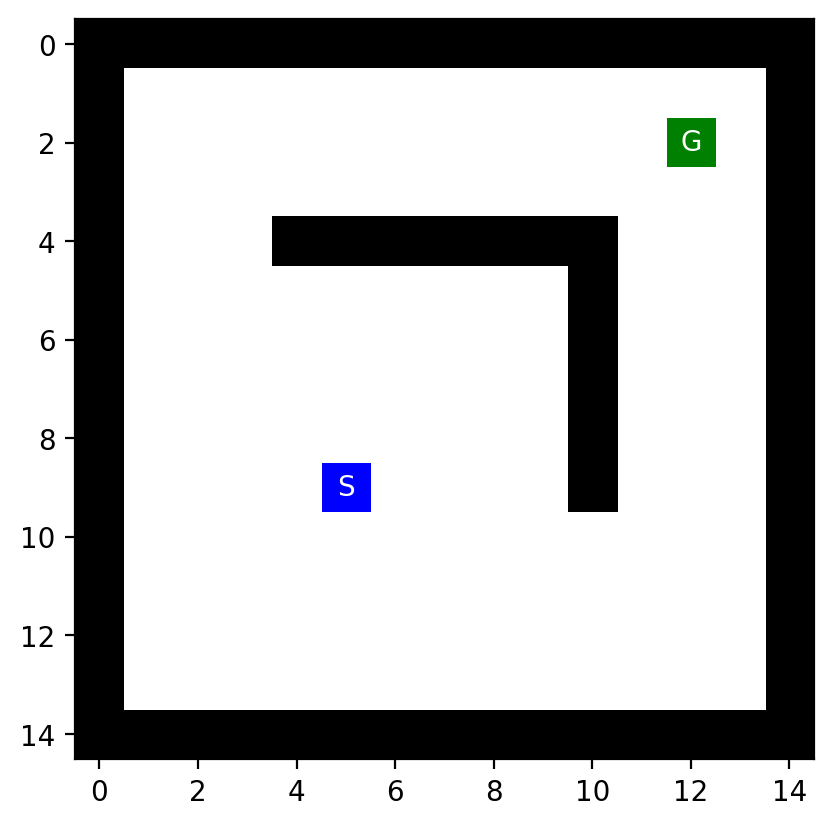

In [1]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

# look at two positions in the maze
print("Position(0,0):", maze[0, 0])
print("Position(8,1):", maze[8, 1])

show_maze(maze)

## Implementation

My implementation follows the pseudo code from the slides/textbook.

In [2]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## Experiments

### BFS

CPU times: user 702 μs, sys: 69 μs, total: 771 μs
Wall time: 773 μs
Path cost: 16 | Expanded: 151 | Max frontier: 17 | Max depth: 16
Actions: EEEESEENNNNNNNNE


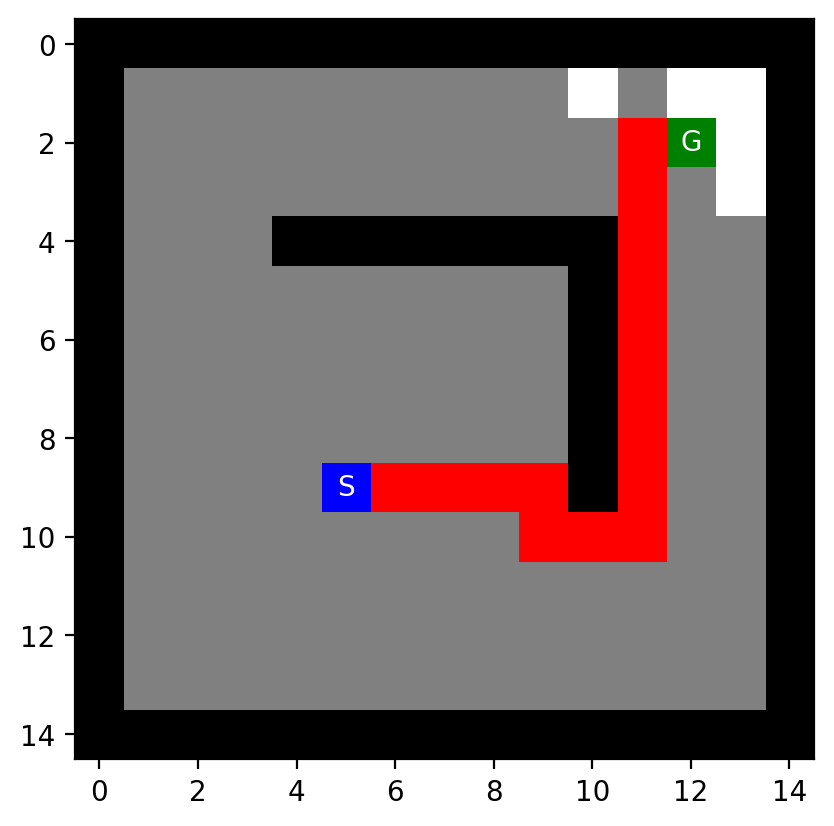

['E',
 'E',
 'E',
 'E',
 'S',
 'E',
 'E',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'E']

In [3]:
ts.set_order("NESW")
#ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "BFS", debug = False, vis = False)
ts.show_path(maze, result)
result['actions']

### DFS 

This implementation uses not reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we will end up in an infinite loop. Here are possible solutions:
* Stop after a fixed number of tries and return no solution `max_tries`.
* IDS solves this problem.

Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory!

CPU times: user 1.53 ms, sys: 145 μs, total: 1.67 ms
Wall time: 1.68 ms
Path cost: 122 | Expanded: 132 | Max frontier: 109 | Max depth: 121
Actions: WWWWSSSSEEEEEEEEEEEENWWWWWWWWWWWNEEEEEEEEEEENWWWWWWWNEEENWWWWWWWWNEEEEEEEENWWWWWWWWNEENWWNEEEEEEEEEESSSSSSEENWNENWNENWNENW


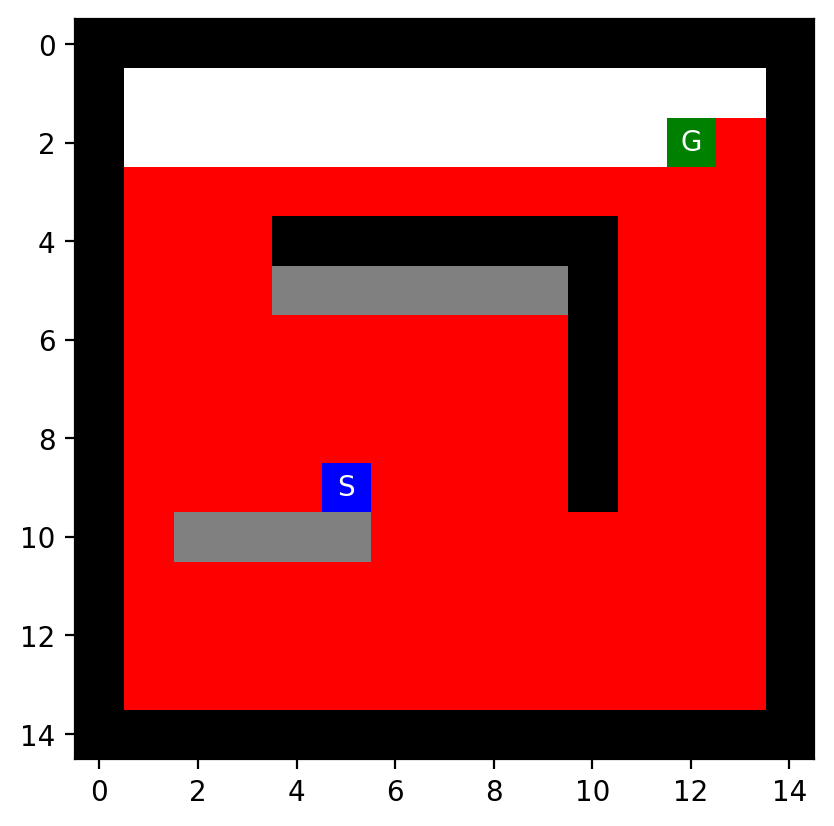

In [4]:
# Note: DFS uses LIFO so the directions come from the stack in reverse order!

# Can get stuck for empty maze since cycle checking is not string enough! 
# I use a maximum number of tries and stop if the goal is not reached.
ts.set_order("NESW")
#ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

Do the same, but change the order in which we explore states (add them to them as nodes to the frontier).

CPU times: user 239 μs, sys: 23 μs, total: 262 μs
Wall time: 264 μs
Path cost: 26 | Expanded: 26 | Max frontier: 30 | Max depth: 25
Actions: WWWWNNNNNNNNEEEEEEEEEEEESW


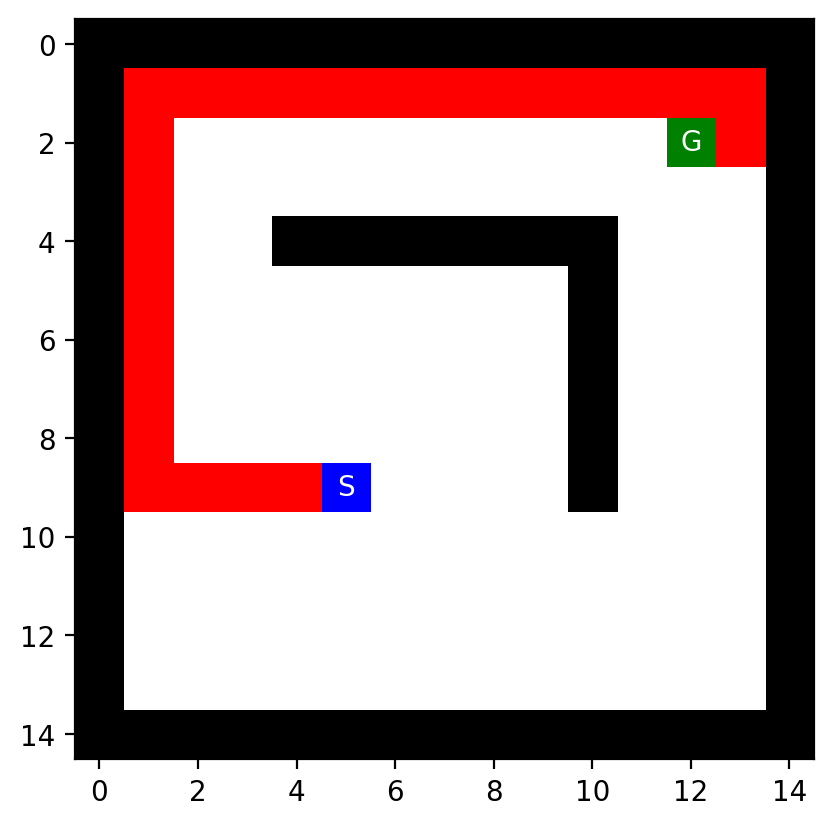

In [5]:
#ts.set_order("NESW")
ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

We could do a random walk and not check for cycles. This is guaranteed to reach eventually any square including the goal, 
but creates a long path. The path could be simplified leading to the [Tremaux's algorithm](https://en.wikipedia.org/wiki/Maze_solving_algorithm).

CPU times: user 5.4 ms, sys: 122 μs, total: 5.52 ms
Wall time: 5.5 ms
Path cost: 742 | Expanded: 742 | Max frontier: 1941 | Max depth: 741
Actions: EWNEWEWWEWEWNSSESSEENWEWWEENWNEENWWESEEWSSNENNWENNSSWESNSWESWNNSENWSWSNSWNEESESNWSWNSNNENESNSWWEEWWENENNWSNEWSSESSSNSEWESSWNEESEESWWWENESNWWNNSWNSESEWSWEWEWWEENSWWNEWEWESEEWWWEWNENSNSESEEWWWWNWSNNWENEEWENNWWNSWENWENESWSENNWESWESEWNEWNWWEEWEWNSNEWSNWEEESSWWSSESSEWSNEEWSNSENSNNEWEEWNSWWSNWNSWEESWESSWENEWSNWNSNSNSSNSENNSWEWWEWESNEESENWEENSSNWWEWNNEWEWENESNWEEWWSEWEWWWEEEWSNSENSWWWNWSWSNWESWEWWEWWSWWENNWWEESNWNNEESNSENNEWSENNEESESNNWWWSWWSWENSSSSNNNWNWNWNSESNWNEEESNEWWWENEWWNENNEEWSWNSWESNNNWEWEESWSWNNESESNSWEEEWNENEESWEWWESNWSNNSESWENENWWWWSENESNSESWNNSWEEWNESNSWNWWEWEEEWSWWNWWESSWNWNEWEWSSEESWSWEENNNWWEWEWNEEWSSENEWEESWENNEEWEEWESENWWWSEWSWNEEESEENSWWNENSSEWENNSWNWWWEWEEEWSNSENEWWWWSSNNSWWESEEENNWEEWWEEWESESESSESENSWNSSNNNEWESNSNNNNSW


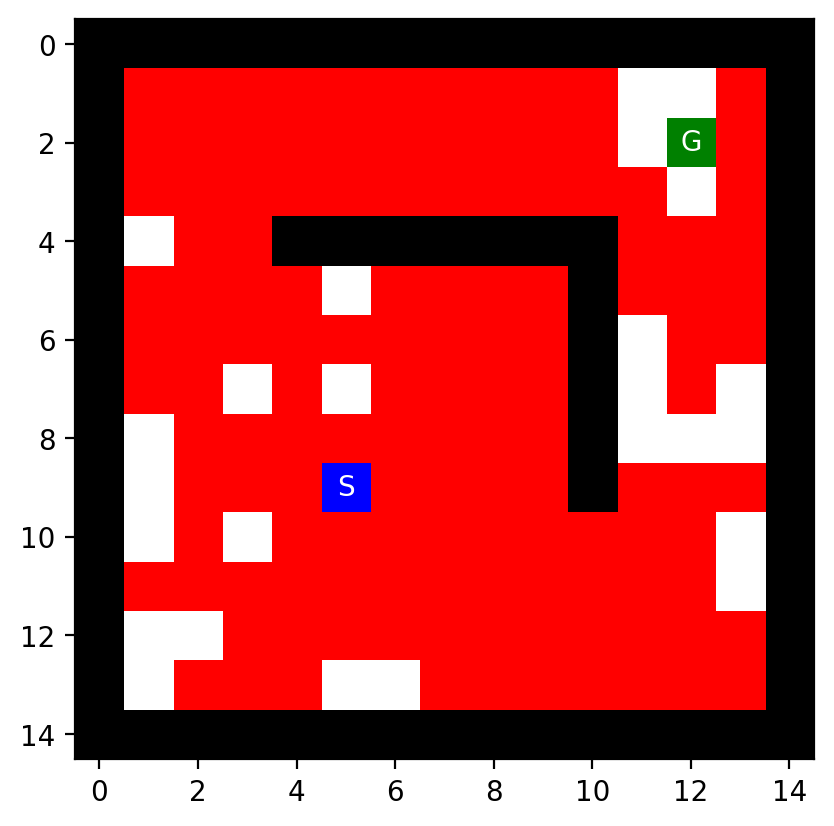

CPU times: user 7.12 ms, sys: 281 μs, total: 7.4 ms
Wall time: 7.33 ms
Path cost: 586 | Expanded: 586 | Max frontier: 1556 | Max depth: 585
Actions: WEESSSNSNWESSWWWNSEWWENSWNWENEESNWWWEESEEESENESNNENSWWNWEEWWNESNWNWWNNNSEWNESNSSNWNSENSNSNSEESNENWESENSSNWSSEWESSSSNNWNNSWNWNEWNSWWESWWEEENEEENWWNWSNSENSNESENSSNSNSWWENNWWWWEEWEWWSNSWNWNSEEEESEESWSENWSWSENSENESNWWWSSWWSWENWSEWSNNNWEEWNWSNNEESSNSEENEWNEWEEESWSWSENSSWNSEWWWSSEWWEWEEEENSEWEWWNEWWESWNNENWESSSNNWWEWSSNSNEWEWEWWESWNSNWWWNESESWWEWNSNSNNNEENSESESESNNWSEWWEWNEENNSENENSEWESNSNWWSENSWSWEWNWEWENESSSNWSSEEEENENNNEENWESNSSWSENWEWESNWESSSNWSNEWSNNSNWENWESESNNNNWESWWENNWEWESWNNSEWNSESSWEWEWNSEWSSWWENENSWEWENNEWEESSNSSWNSWWNSSSNENNSNNSSSNNSWSSEEWEWNWNEWNEENSWNNNENWNNNNSWWNEWEESNE


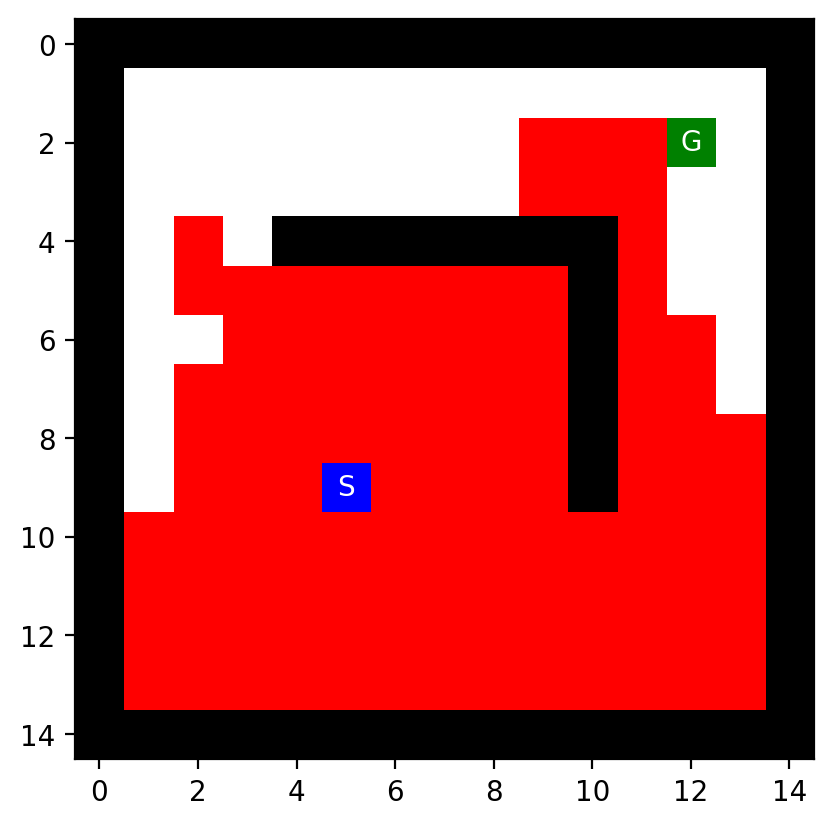

CPU times: user 5.39 ms, sys: 0 ns, total: 5.39 ms
Wall time: 5.37 ms
Path cost: 760 | Expanded: 760 | Max frontier: 2010 | Max depth: 759
Actions: NNNEWSWNNSNSWENEWWWWEWEEEEEEEESWSWNESSNENSNSNWEWESSNSSNSWSWWSNWNNWENNSWEWNNSNSWWSNNNNSESEWEWESESSNNSWWSNWSSNESWNSENSNNNNEWWNNNSNENSWWSSSSSNSEESWWNEESSEWNWNSESENNEWESSNEWSSSWNEESWSSEWNSNNNENEEWWNESNSWWESNNSSWSWENNSNEESSWSNSNESNEENWSNENWSEEWNWNNENWWEWSEESNNNSWWEEWNSNWESWWNSWWNWNNWNENWWEEWSWSESENWSESEESNEWWESSWWNWSWNEENSSSEWEEWWNSNSNSWNENENEEESSNNEESSNNWSNWSSSSEESWSNNSSESNNSEEENSENNNNNSSSWENWEWNEWWSNEWNNSSSNSSESNENSSNSSWSWNSNEWESNESNNWENNWEWSENWSSENWSWEESSSNNSWSNWEWNWEWNENNNSEESNWNWEWESESWNSWSNEEWWEWSEENSWSSWNWNSSWEWNESWSWEWWWNSNSWNEENNSNNEEWWSNWNWNWSNNNWNSWNSSWEENESEWENSWNSEENEEEWWESSWEWNEENWWWESSNSENSSWWSEEWWNSSSSEESWWENSNEEWEESWWENWWSENENNWEESNEWEEWSSSNWSNNWENSNSSEWNNESWNEESSSEWENSWNSNNSWENESWSNNENWNENWSWNESESWWNSNSSNSEEWNENNNWNSWEEWENNNWNWEEWEWWESNN


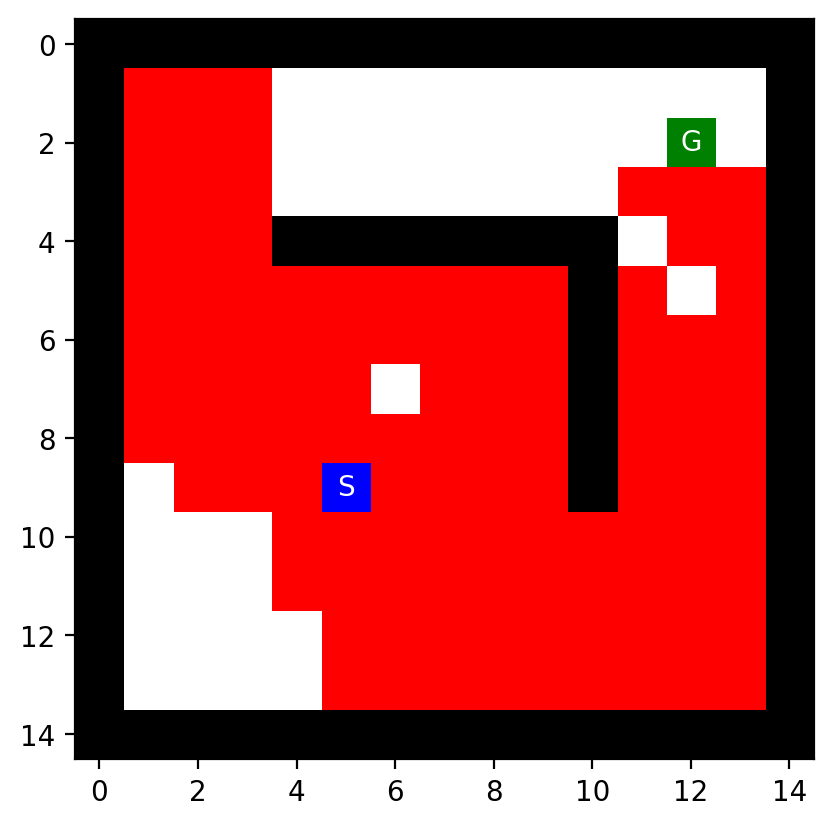

CPU times: user 5.97 ms, sys: 158 μs, total: 6.13 ms
Wall time: 6.12 ms
Path cost: 816 | Expanded: 816 | Max frontier: 2175 | Max depth: 815
Actions: SWESSSEENWNESENSSNSEWENNSWEESNNENNNNNNNSESWNESSWSNSNNESWSNSSNEWEWEENWNNSNWNEENSWWESWENNSNSSSSESSNWWEESNNSSNWNWSSEWNESNSESNWNESWSSENNNNWEWSNWNSESESSWSNSWSEESNWESWNWSNNENWSWNSNEESNEWWWSSNWWWWENEEESEWENSWWSNNWEWSSSENEWSEWWNWNESEEEESWWNSWNWEESWENENESSWNESWWEWEWWNSNNSWNNWNSSSWEWESNNNWSENWNSNWSWEWENWWESSNEWWENESENWNSSEWSWSWWNSNNNNNNWSEWSEEWEEWESEWEWSNWSENEWSESWEWEENWESSWWNSWNSESENSWNSENWEEEWNEWESEWSEEENNENSWSESEEWNSNESNWENSWENNSWSEWENSWNWSWWWSEEEWWNWNSSEWEWWWEWWEWWNEWSWEWEEWENWEWNWWEEWEWNEENWWSWNSNNNSWNSEWSSSENWESNSESWENNEEWENESSSNWWWSESNNNWWSNEWWSNEWNNSSNSNNEEENSWWESWEWWNSSSNNESWESEWSENENEESWWNSWEWESEWSNNEENSSWESNWSEWENSEEEWWENSNWSENWNNSNEWWSSNWENNEWWSWSNNESEWWSWEWESNSWNWNNWSEWNENEWNWESEESSNEEWNENNWESNEEWSSEWSNNWSSWSWWNSENSESENSWSSEEWEENESNNWWEWENSSESEENSWWNNEEESENWESSWEWWENNENSWNSESWNEWSNNNWNNEENSNNSSNNWENNNW


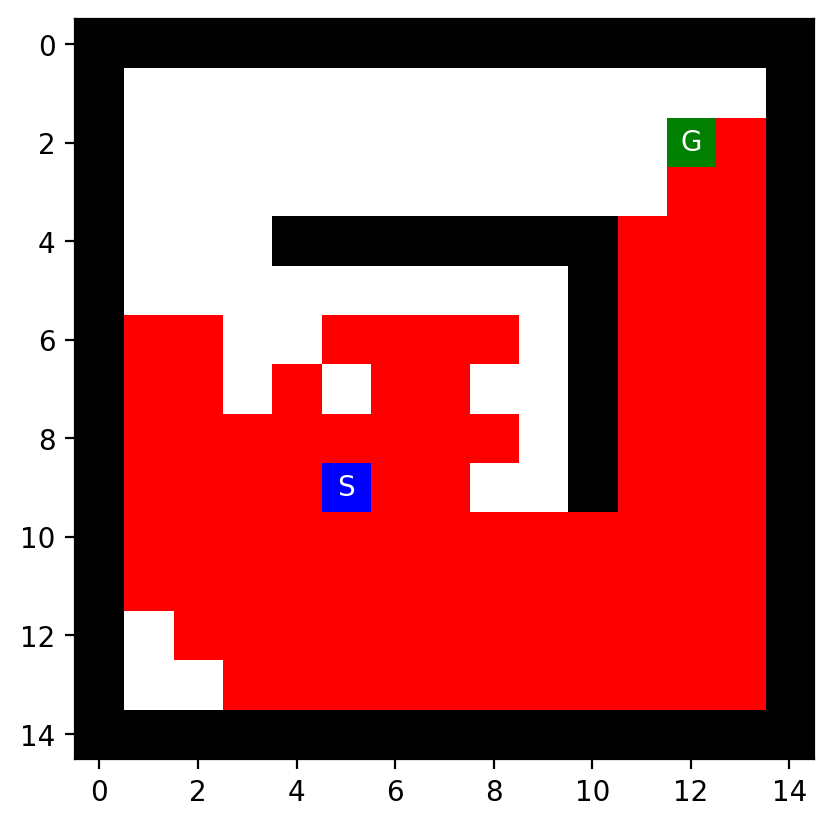

CPU times: user 6.54 ms, sys: 0 ns, total: 6.54 ms
Wall time: 6.53 ms
Path cost: 522 | Expanded: 522 | Max frontier: 1384 | Max depth: 521
Actions: WNEWWESSWEENWWNSSWNSNNSEEWNNNNESENEWSNWEESWNEWWSEESNNWWWWSNEESSNEWEWENSNWWESWNSNEEEEWWEWEWSWWWWNEWNSNNNEWENWEWESSNNSENWSNEEEESNSNSWNWESEWSNWSWSSWWNNSESWNESNNSESNNSWWSSNESENEWESNSWWNWEWENNSENENEWEWEESWWENNSWESEEWEENNSEWSNENSSNSEWWEWWWWNSNWWNWSWSSENNSEWWSSEEWWSENENSSNSEEESWSNNSNWSSNEWEEEENNEWWWSSEEWEEWSNWWENSNNWEWSSWNWNESNSSSNSWESSWNSNWSEWNWNWEEWSSSNSEWESESNENNWEWSNEWNSNSWESSSNWSEWEENNEWSNNEEEWWSSSWWNSENNEENWEENENWESSWSWESNENWSEWESSEWEENWWWSENSNEWSENEESWEWNWNEEWESEWEWWWENSNESNWENNNWNSNNENWNNEWWEWNEWEWSESEWNSSNNSNWESNNE


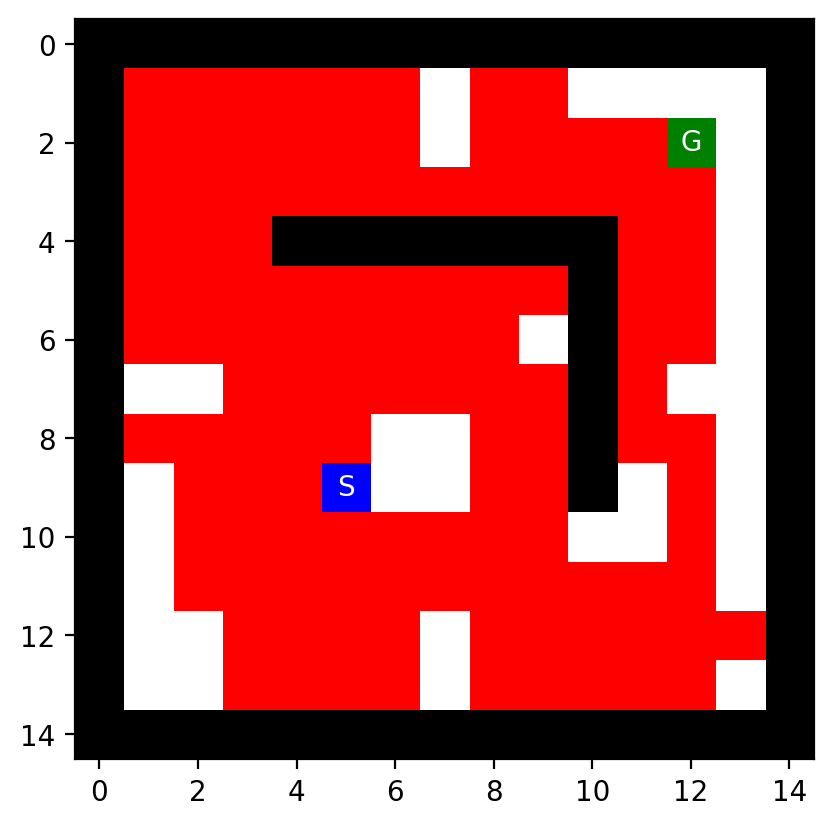

In [6]:
ts.set_order(random = True)

# run it multiple times to see the effect of randomization
for _ in range(5):
    %time result = ts.DFS(maze, check_cycle = False, max_tries = 100000, vis = False, debug_reached = True)

    #result
    ts.show_path(maze, result)
    if result['path'] is None:
        print("No solution found!")

### Run randomized DFS multiple times and use the best solution.

__Note:__ IDS takes a similar amount of time and memory, but is guaranteed optimal.

CPU times: user 3.16 s, sys: 39.3 ms, total: 3.2 s
Wall time: 3.2 s
Solutions have path_lengths of [54, 58, 82, 98, 52, 44, 44, 58, 64, 48, 44, 92, 88, 86, 78, 68, 58, 88, 68, 64, 86, 102, 40, 78, 58, 86, 48, 72, 42, 32, 46, 86, 68, 92, 74, 54, 38, 90, 92, 80, 78, 54, 80, 82, 66, 82, 34, 40, 60, 48, 92, 80, 68, 54, 44, 58, 66, 74, 50, 52, 32, 92, 64, 86, 82, 48, 62, 40, 70, 54, 40, 102, 58, 72, 58]
Path cost: 32 | Expanded: 32 | Max frontier: 42 | Max depth: 31
Actions: NNNNWSWWWNNNESSENNEEEENNEESSEENE


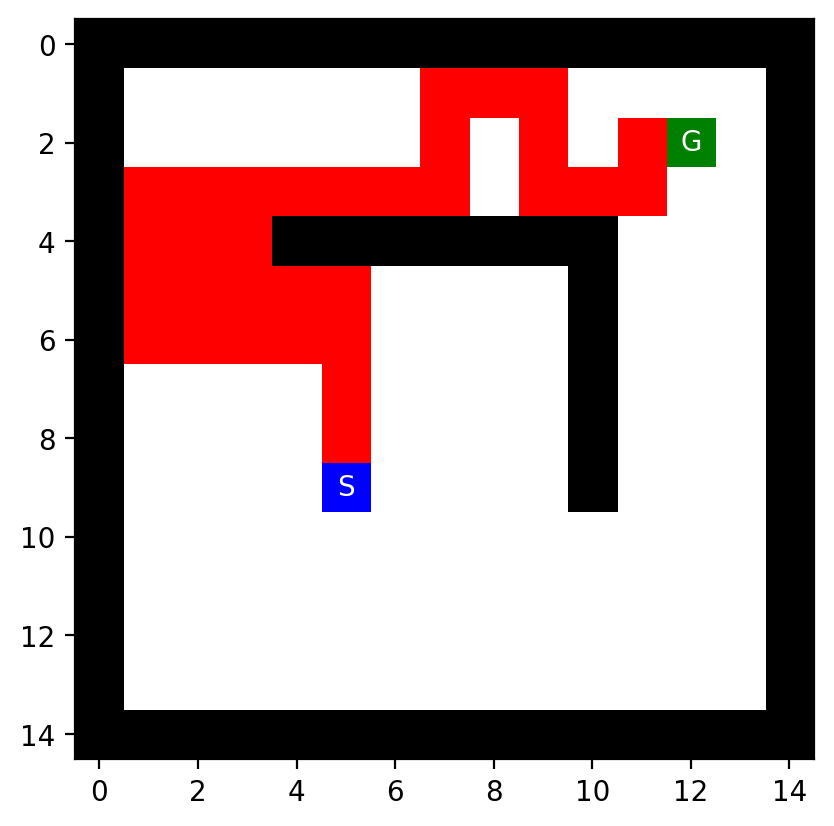

In [7]:
ts.set_order(random = True)

N = 100
%time results = [ ts.DFS(maze, max_tries = 10000, vis = False) for _ in range(N) ]

# check if we found a solution and display the best solution
results = [ r for r in results if not r['path'] is None ]
if len(results) > 0:
    path_lengths = [ len(r['path'])-1 for r in results ]

    print(f"Solutions have path_lengths of {path_lengths}")

    result = results[ts.min_index(path_lengths)]
    ts.show_path(maze, result)
else:
    print("No solution found!")

### Depth limited DFS

Note: The frontier needs to be checked differently during cycle checking!

In [8]:
ts.set_order(random = True)

%time result = ts.DFS(maze, limit = 5, frontier_option = 2, max_tries = 100000, vis = False, debug_reached = True)
ts.show_path(maze, result)

CPU times: user 1.39 ms, sys: 0 ns, total: 1.39 ms
Wall time: 1.39 ms
No solution found; expanded: 346 ; terminated at max_tries: False


### IDS

__Notes:__ 

* IDS with DFS does not store reached squares, so gray areas are not shown!

* IDS depends on the cycle checking of DFS and therefore is also affected by these problems.

CPU times: user 15.5 ms, sys: 0 ns, total: 15.5 ms
Wall time: 15.3 ms
Path cost: 16 | Expanded: 3430 | Max frontier: 21 | Max depth: 16
Actions: SEEEEEEENNNNNNNN


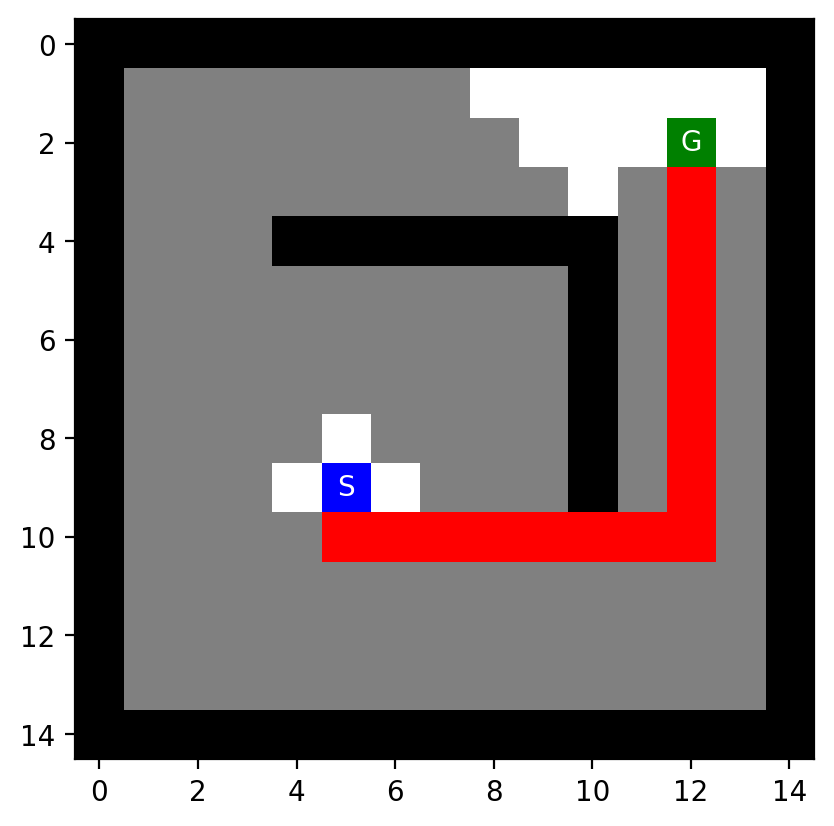

In [9]:
ts.set_order(random = True)

%time result = ts.IDS(maze, frontier_option = 2, max_tries = 100000)
ts.show_path(maze, result)

### Greedy Best-First Search (GBFS)

In [10]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

CPU times: user 446 μs, sys: 18 μs, total: 464 μs
Wall time: 466 μs
Path cost: 18 | Expanded: 43 | Max frontier: 32 | Max depth: 17
Actions: EENEESSEENNENNNNNN


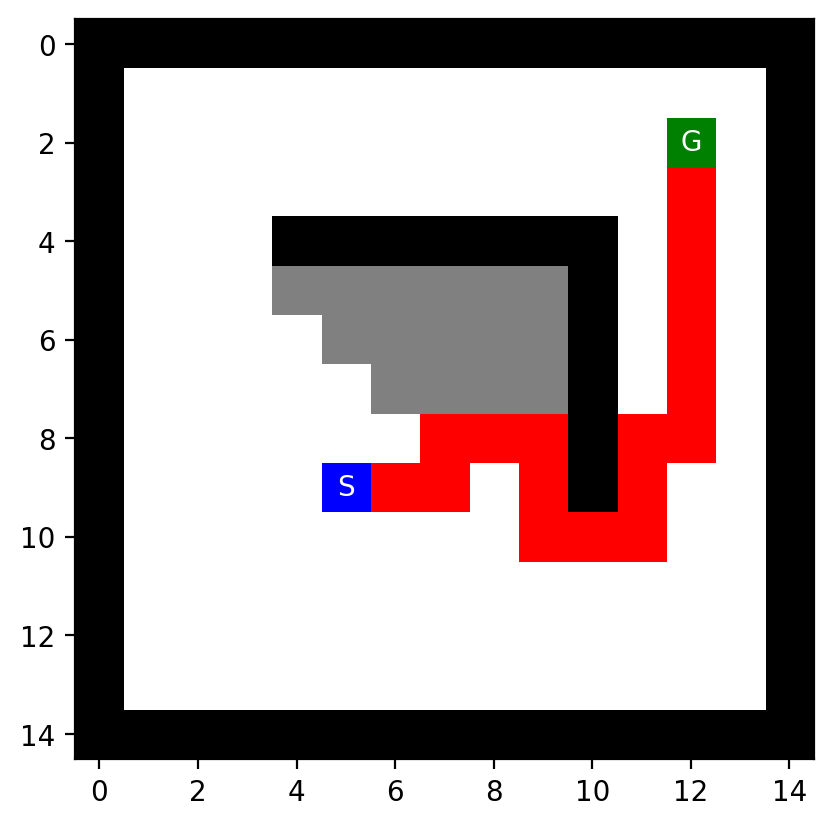

In [11]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "GBFS", debug = False, vis = False)
ts.show_path(maze, result)

### A* Search

CPU times: user 529 μs, sys: 22 μs, total: 551 μs
Wall time: 554 μs
Path cost: 16 | Expanded: 40 | Max frontier: 38 | Max depth: 15
Actions: EEEESEENENNNNNNN


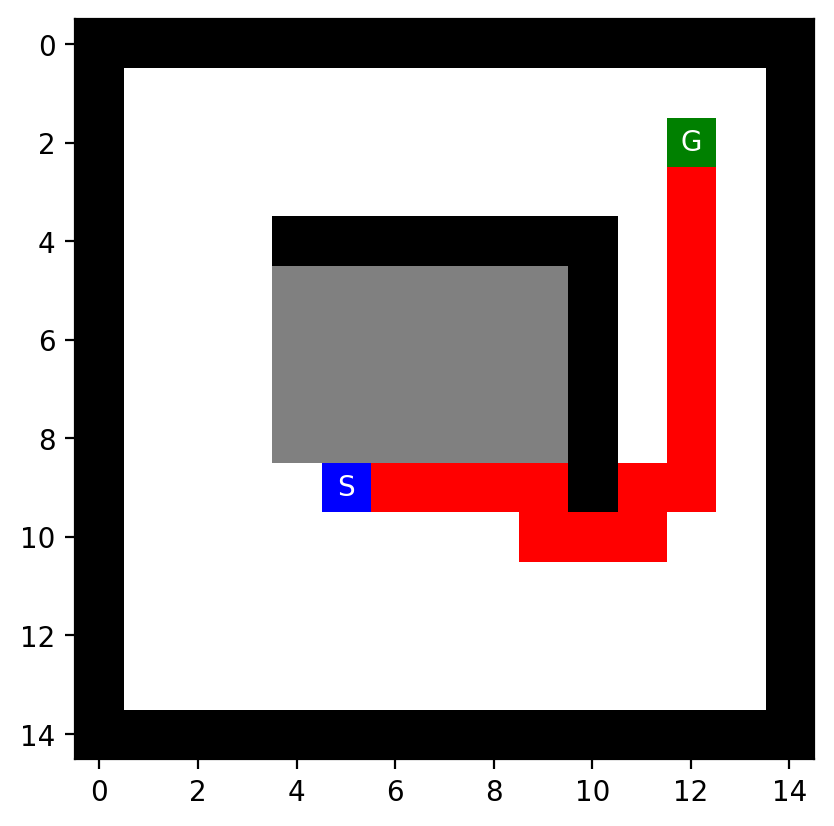

In [12]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False)
ts.show_path(maze, result)

### Weighted A* Search

$W > 1$ tends towards GBFS (optimality is not guaranteed)

CPU times: user 516 μs, sys: 21 μs, total: 537 μs
Wall time: 541 μs
Path cost: 16 | Expanded: 36 | Max frontier: 32 | Max depth: 15
Actions: EEEESEEENNNNNNNN


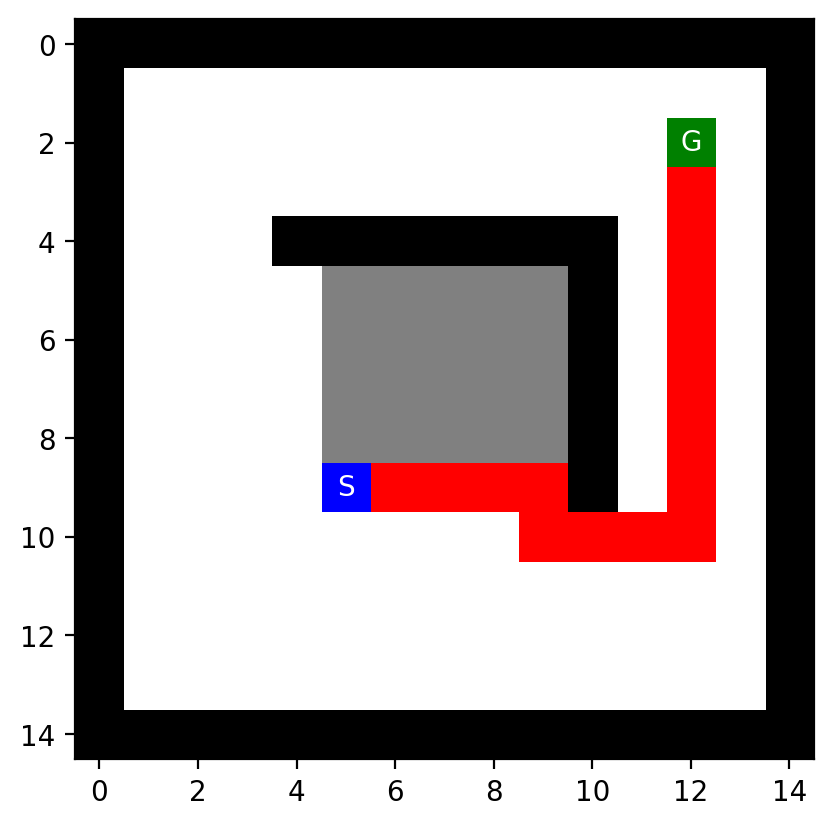

In [13]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", W = 1+1e-9, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: user 490 μs, sys: 20 μs, total: 510 μs
Wall time: 514 μs
Path cost: 18 | Expanded: 48 | Max frontier: 33 | Max depth: 17
Actions: NEEEESSEEENNNNNNNN


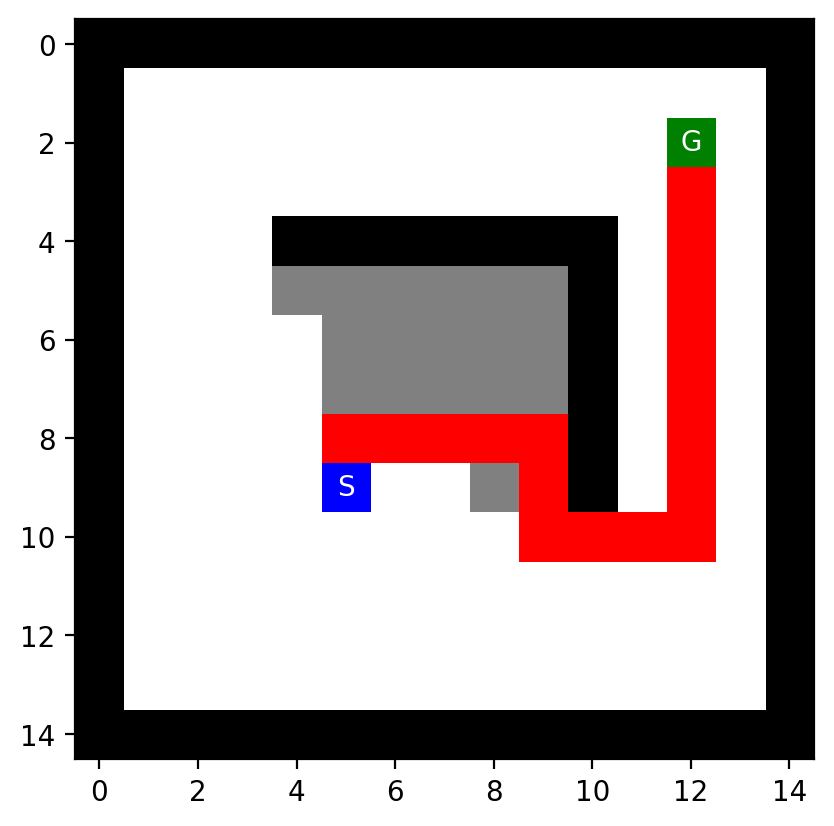

In [14]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 5, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: user 509 μs, sys: 0 ns, total: 509 μs
Wall time: 508 μs
Path cost: 18 | Expanded: 40 | Max frontier: 31 | Max depth: 17
Actions: ENEEESSEEENNNNNNNN


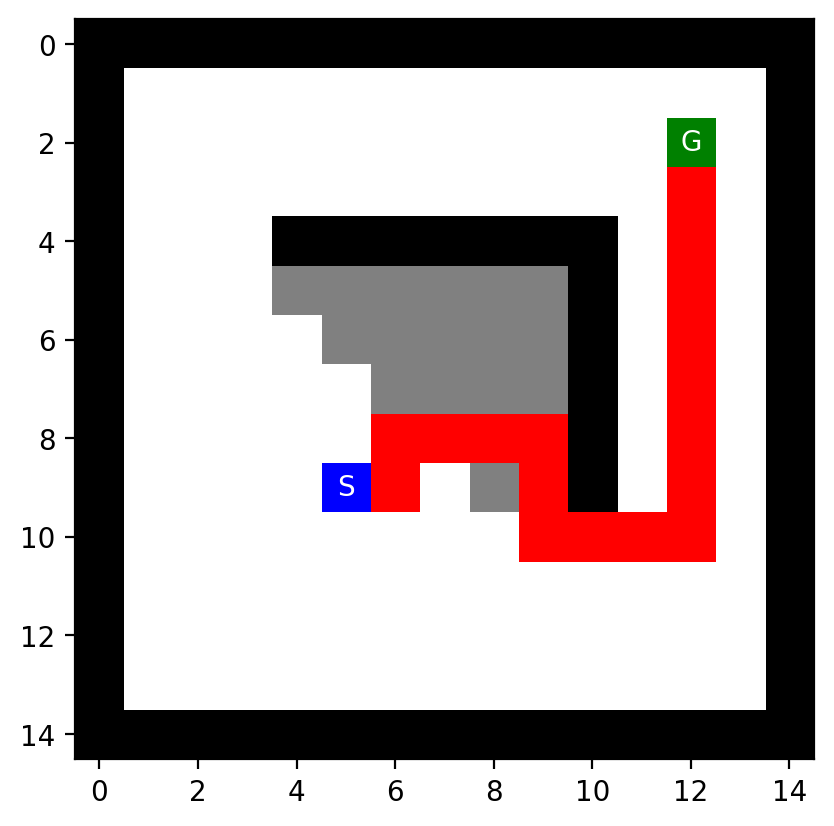

In [15]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 1000, debug = False, vis = False)
ts.show_path(maze, result)

$W<1$ tends towards Uniform-Cost Search/BFS (optimality is guaranteed)

CPU times: user 942 μs, sys: 42 μs, total: 984 μs
Wall time: 987 μs
Path cost: 16 | Expanded: 88 | Max frontier: 35 | Max depth: 15
Actions: EEEESEENNNNNNNNE


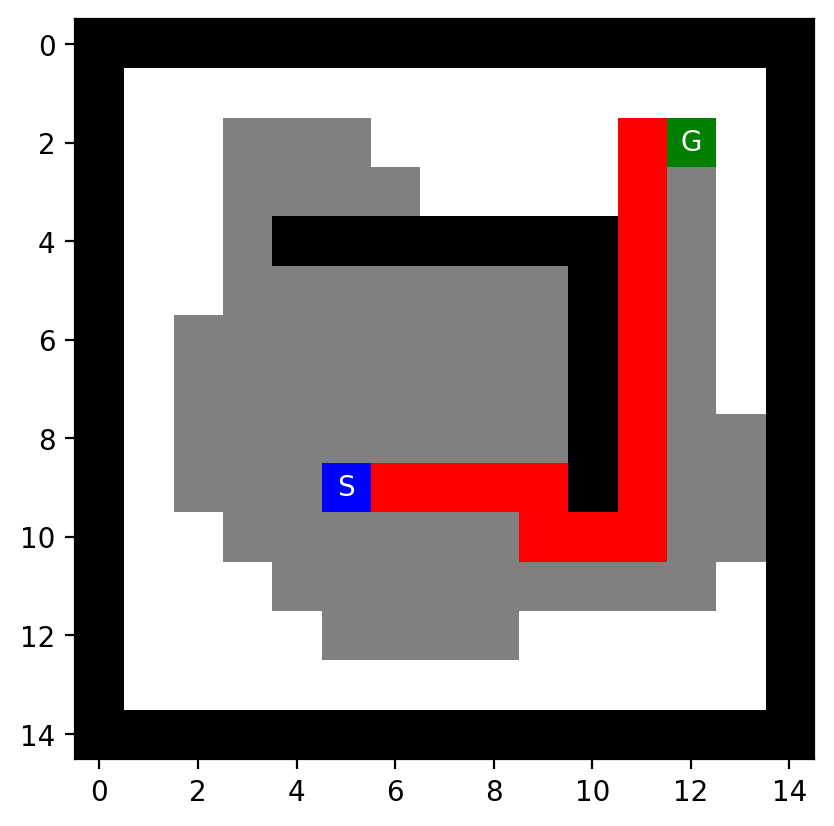

In [16]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .7, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: user 1.78 ms, sys: 0 ns, total: 1.78 ms
Wall time: 1.78 ms
Path cost: 16 | Expanded: 148 | Max frontier: 18 | Max depth: 15
Actions: EEEESEENNNNNNNNE


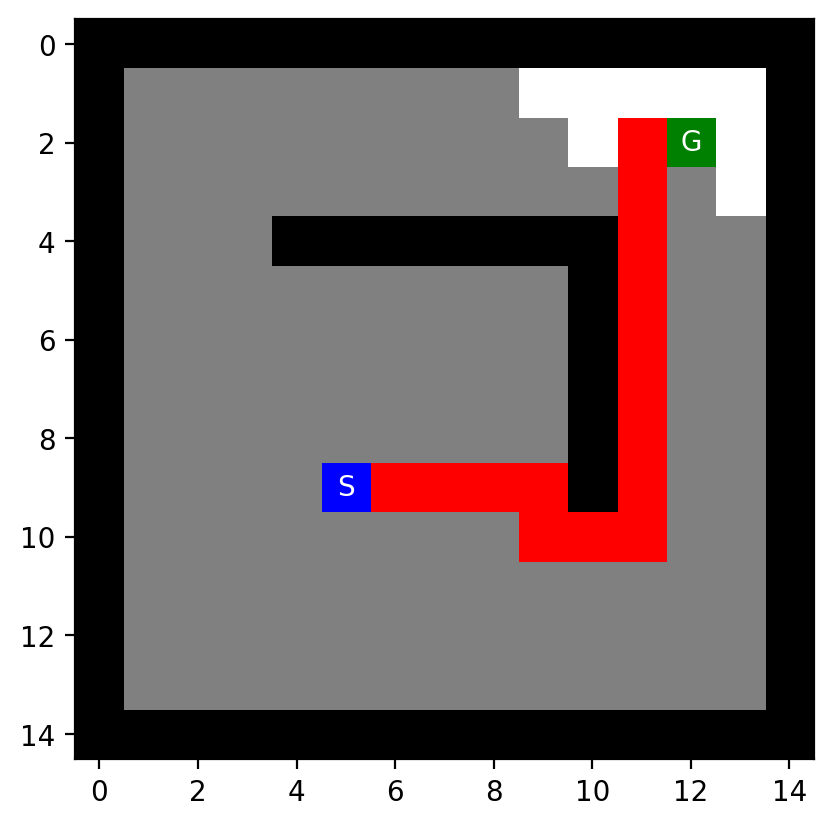

In [17]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .0001, debug = False, vis = False)
ts.show_path(maze, result)

### Compare Timing

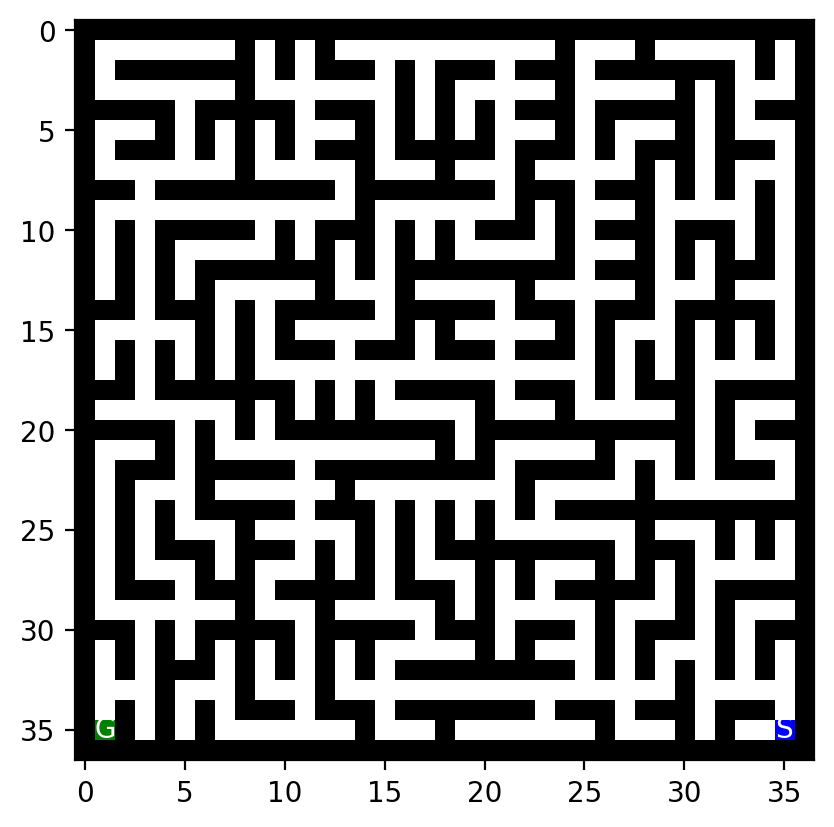

In [18]:
#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("L_maze.txt", "r")
#f = open("loops_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

ts.show_maze(maze)

ts.set_order(random=True)


In [19]:
import timeit
import math

reps = 10

times = {}

algorithms = ["BFS", "DFS", "GBFS", "A*"]

### FIXME: add IDS

for a in algorithms:
    times[a] = math.ceil(timeit.timeit(stmt = f'ts.best_first_search(maze, strategy = "{a}", debug = False, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)
    
times['DFS(no reached)'] = math.ceil(timeit.timeit(stmt = f'ts.DFS(maze, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

times['IDS'] = math.ceil(timeit.timeit(stmt = f'ts.IDS(maze, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

In [20]:
import pandas as pd
df = pd.DataFrame(times, index = ["time in micro seconds"])
df

,BFS,DFS,GBFS,A*,DFS(no reached),IDS
time in micro seconds,3244,2521,2936,4745,6737,281453


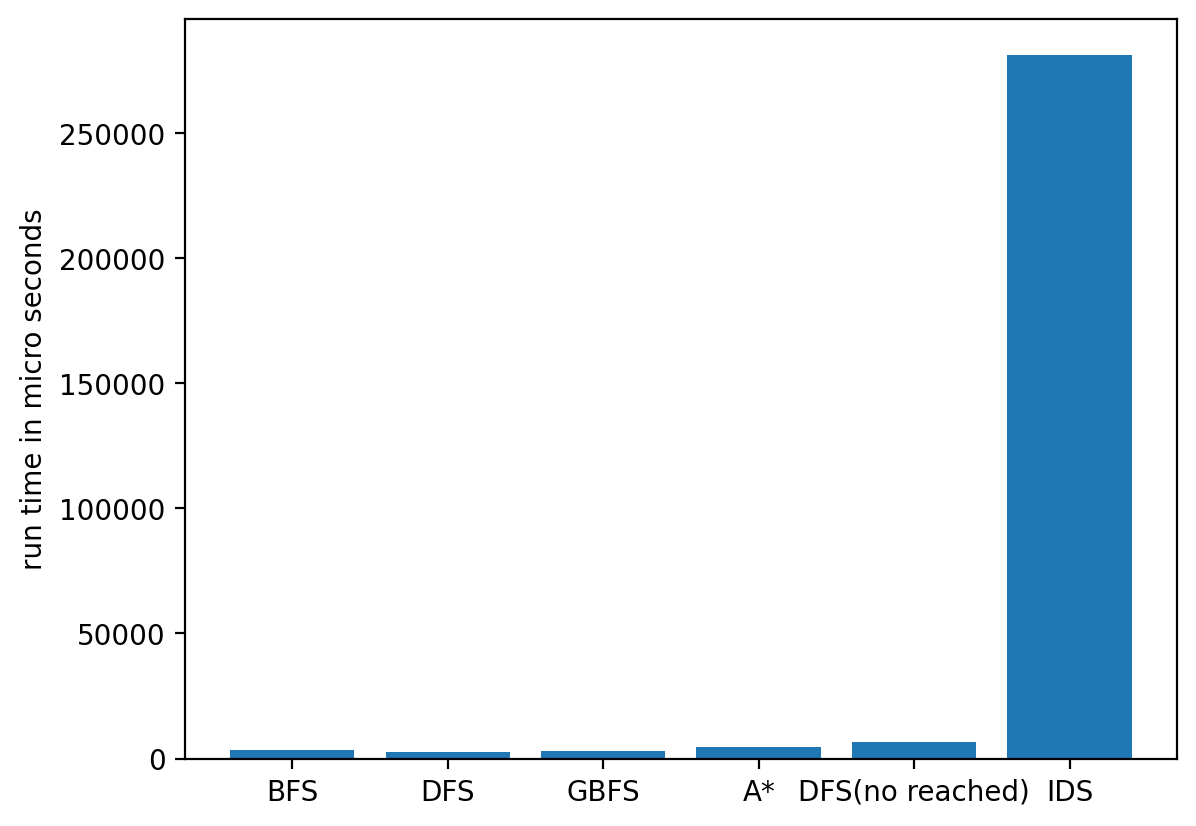

In [21]:
import matplotlib.pyplot as plt

plt.bar(df.columns, height = df.iloc[0])
plt.ylabel("run time in micro seconds")
plt.show()

---
# BÀI 3. TÌM KIẾM KHÔNG THÔNG TIN: BFS VÀ DFS

**Yêu cầu:** (1) Chạy BFS, theo dõi queue/frontier, số nút mở rộng và đường đi; (2) chạy DFS nhiều lần khi thứ tự sinh trạng thái ngẫu nhiên; (3) giải thích FIFO/LIFO, tính đầy đủ, tối ưu và bộ nhớ. 

> **Nguồn chương trình:** Các cell bên trên được giữ theo notebook gốc. Tệp `tree_search_solution.py` đi kèm là **bản cài đặt độc lập phục vụ bài thực hành**, nhằm thay thế module tác giả ghi là *not published*; không khẳng định là phiên bản chính thức. Phần dưới đặt dữ liệu `small_maze.txt` riêng để tránh biến `maze` đã bị đổi sang `large_maze.txt` ở mục Compare Timing.

**Quy ước đo lường:** `n_expanded` đếm những lần lấy nút khỏi frontier và **thực hiện mở rộng nút con** (không tính lần lấy đích ra để kiểm tra). `max_frontier` là số phần tử cực đại thực tế trong cấu trúc dữ liệu. DFS dùng **kiểm tra chu trình trên đường đi hiện tại**, tránh lặp vòng trong một nhánh nhưng có thể gặp lại cùng trạng thái ở nhánh khác.

## 3.1. Mô tả thuật toán BFS (Breadth-First Search)

BFS duy trì **Queue (FIFO)**, nghĩa là trạng thái được thêm trước sẽ được xét trước. Thuật toán bắt đầu tại ô `S`, lần lượt mở rộng các trạng thái theo độ sâu tăng dần cho đến khi lấy được trạng thái `G` từ queue. 

Các bước: (1) Thêm nút gốc vào queue; (2) lấy nút đầu queue; (3) nếu là `G`, truy hồi chuỗi hành động qua `parent`; (4) ngược lại, sinh các trạng thái hợp lệ và chưa phát hiện để thêm vào cuối queue; (5) tiếp tục cho đến khi tìm thấy đích hoặc queue rỗng.

Trong mỗi mê cung, di chuyển theo bốn hướng `N, E, S, W` có chi phí bước bằng 1, vì thế BFS tìm đường đi **ngắn nhất theo số bước**. Tập `reached` được sử dụng để không thêm cùng một trạng thái nhiều lần.

BFS - small_maze
Trạng thái bắt đầu: (np.int64(3), np.int64(11))
Trạng thái đích: (np.int64(8), np.int64(1))
Độ dài đường đi tối ưu: 19
Số nút được mở rộng: 92
Max frontier: 9
Dãy hành động: E -> E -> S -> S -> W -> S -> S -> W -> W -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W
Đường đi: [(np.int64(3), np.int64(11)), (np.int64(3), np.int64(12)), (np.int64(3), np.int64(13)), (np.int64(4), np.int64(13)), (np.int64(5), np.int64(13)), (np.int64(5), np.int64(12)), (np.int64(6), np.int64(12)), (np.int64(7), np.int64(12)), (np.int64(7), np.int64(11)), (np.int64(7), np.int64(10)), (np.int64(8), np.int64(10)), (np.int64(8), np.int64(9)), (np.int64(8), np.int64(8)), (np.int64(8), np.int64(7)), (np.int64(8), np.int64(6)), (np.int64(8), np.int64(5)), (np.int64(8), np.int64(4)), (np.int64(8), np.int64(3)), (np.int64(8), np.int64(2)), (np.int64(8), np.int64(1))]
Path cost: 19 | Expanded: 92 | Max frontier: 9 | Max depth: 19
Actions: EESSWSSWWSWWWWWWWWW


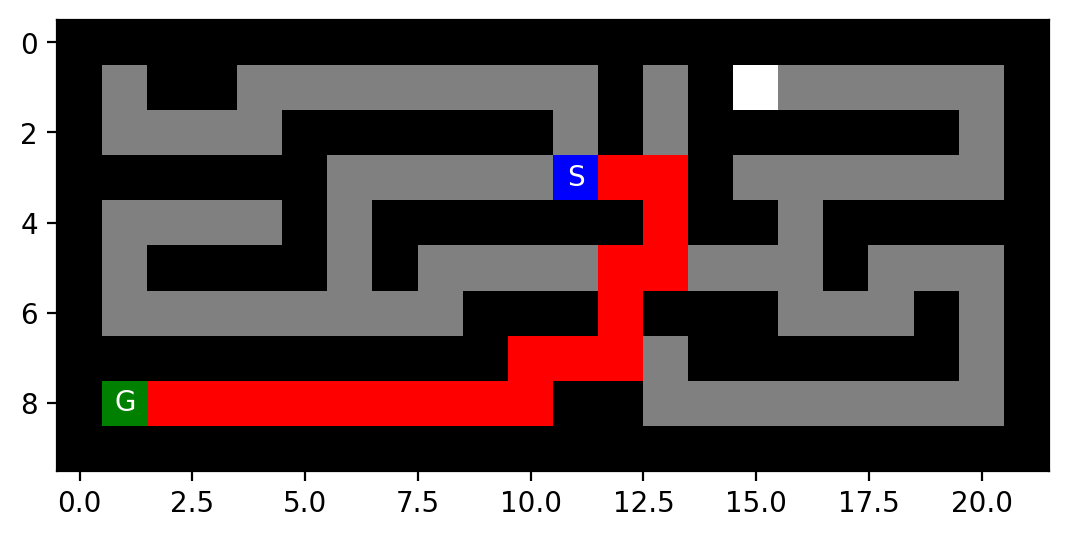

In [22]:
import tree_search_solution as ts
import maze_helper as mh
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

# Đọc dữ liệu trực tiếp; không sử dụng biến maze bị thay đổi từ các mục gốc.
with open('small_maze.txt', encoding='utf-8') as file:
    maze_bai3 = mh.parse_maze(file.read())

ts.set_order('NESW')
bfs_bai3 = ts.best_first_search(maze_bai3, strategy='BFS')
assert bfs_bai3['path'] is not None
assert len(bfs_bai3['actions']) == bfs_bai3['path_cost']
print('BFS - small_maze')
print('Trạng thái bắt đầu:', mh.find_pos(maze_bai3, 'S'))
print('Trạng thái đích:', mh.find_pos(maze_bai3, 'G'))
print('Độ dài đường đi tối ưu:', bfs_bai3['path_cost'])
print('Số nút được mở rộng:', bfs_bai3['n_expanded'])
print('Max frontier:', bfs_bai3['max_frontier'])
print('Dãy hành động:', ' -> '.join(bfs_bai3['actions']))
print('Đường đi:', bfs_bai3['path'])
ts.show_path(maze_bai3, bfs_bai3)

### Quan sát frontier của BFS

Ở từng bước, queue giữ các trạng thái đã phát hiện nhưng chưa mở rộng. Mỗi vòng lặp, phần tử đầu tiên được lấy ra, còn các nút con hợp lệ chưa được phát hiện được thêm vào cuối queue. Để dễ theo dõi, bảng dưới chỉ liệt kê tối đa 25 tọa độ đầu tiên của frontier tại mỗi bước. `frontier_size` mới là kích thước thực của toàn queue.

In [23]:
frontier_bfs = pd.DataFrame(bfs_bai3['trace'][:15])
frontier_bfs['frontier'] = frontier_bfs['frontier'].map(lambda xs: ', '.join(map(str, xs)))
display(frontier_bfs.rename(columns={
    'step':'Bước', 'expanded':'Trạng thái mở rộng',
    'frontier_size':'Kích thước frontier', 'frontier':'Các vị trí trong frontier (tối đa 25)'
}))
print('Tổng số trạng thái được mở rộng:', bfs_bai3['n_expanded'])
print('Số phần tử frontier lớn nhất:', bfs_bai3['max_frontier'])

,Bước,Trạng thái mở rộng,Kích thước frontier,Các vị trí trong frontier (tối đa 25)
0,1,"(3, 11)",3,"(np.int64(2), np.int64(11)), (np.int64(3), np...."
1,2,"(2, 11)",3,"(np.int64(3), np.int64(12)), (np.int64(3), np...."
2,3,"(3, 12)",3,"(np.int64(3), np.int64(10)), (np.int64(1), np...."
3,4,"(3, 10)",3,"(np.int64(1), np.int64(11)), (np.int64(3), np...."
4,5,"(1, 11)",3,"(np.int64(3), np.int64(13)), (np.int64(3), np...."
5,6,"(3, 13)",4,"(np.int64(3), np.int64(9)), (np.int64(1), np.i..."
6,7,"(3, 9)",4,"(np.int64(1), np.int64(10)), (np.int64(2), np...."
7,8,"(1, 10)",4,"(np.int64(2), np.int64(13)), (np.int64(4), np...."
8,9,"(2, 13)",4,"(np.int64(4), np.int64(13)), (np.int64(3), np...."
9,10,"(4, 13)",4,"(np.int64(3), np.int64(8)), (np.int64(1), np.i..."


Tổng số trạng thái được mở rộng: 92
Số phần tử frontier lớn nhất: 9


## 3.2. Khảo sát DFS (Depth-First Search)

DFS dùng **Stack (LIFO)**: trạng thái được thêm vào sau cùng sẽ được mở rộng trước. Do đó, thứ tự các hướng được **đẩy vào stack** có ảnh hưởng lớn tới thứ tự tìm kiếm thực tế (khi `set_order('NESW')`, phần tử `W` sẽ được ưu tiên lấy ra trước nếu hợp lệ).

Thực nghiệm thứ nhất giữ thứ tự hướng cố định. Thực nghiệm thứ hai đảo ngẫu nhiên thứ tự sinh con ở mỗi lần mở rộng. Mỗi lần thử đều sử dụng seed khác nhau nhưng công bố seed để tái lập kết quả. DFS có kiểm tra chu trình trên đường đi hiện tại và giới hạn số lần mở rộng nhằm tránh chạy quá lâu trong các không gian nhiều đường vòng.

DFS với thứ tự thêm nút NESW:
Path cost: 29
Nút mở rộng: 39
Max frontier: 5
Hành động: W -> W -> W -> W -> W -> S -> S -> S -> E -> E -> N -> E -> E -> E -> E -> S -> S -> W -> W -> S -> W -> W -> W -> W -> W -> W -> W -> W -> W
Path cost: 29 | Expanded: 39 | Max frontier: 5 | Max depth: 28
Actions: WWWWWSSSEENEEEESSWWSWWWWWWWWW


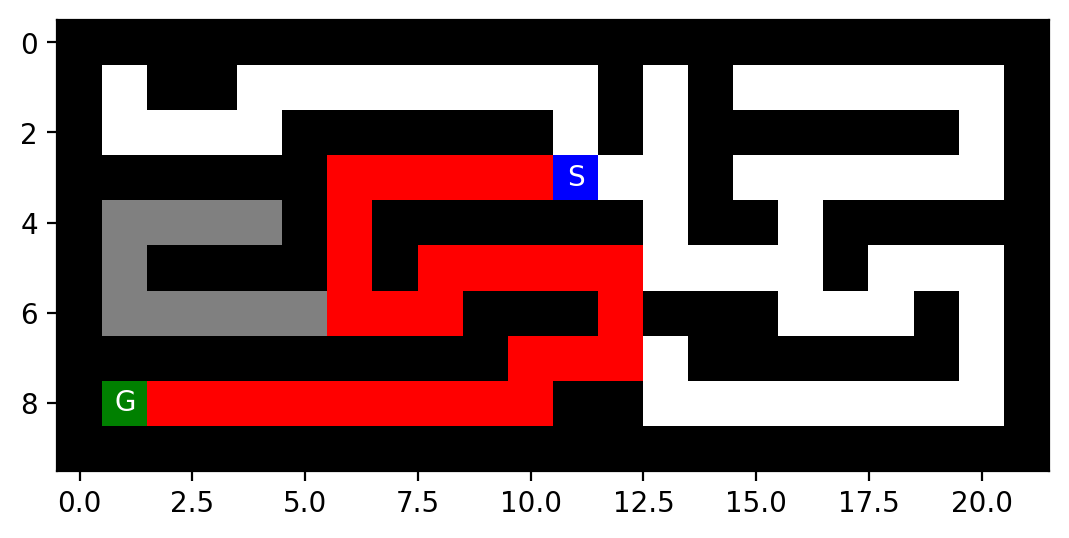

In [24]:
ts.set_order('NESW')
dfs_fixed = ts.DFS(maze_bai3, check_cycle=True, max_tries=30000)
print('DFS với thứ tự thêm nút NESW:')
print('Path cost:', dfs_fixed['path_cost'])
print('Nút mở rộng:', dfs_fixed['n_expanded'])
print('Max frontier:', dfs_fixed['max_frontier'])
print('Hành động:', ' -> '.join(dfs_fixed['actions']))
ts.show_path(maze_bai3, dfs_fixed)

In [25]:
n_runs = 8
rows = []
for trial in range(1, n_runs + 1):
    seed = 20261009 + trial
    random.seed(seed)
    ts.set_order(random=True)
    r = ts.DFS(maze_bai3, check_cycle=True, max_tries=30000)
    rows.append({
        'Lần chạy': trial, 'Seed': seed,
        'Đường đi (bước)': r['path_cost'],
        'Nút mở rộng': r['n_expanded'],
        'Max frontier': r['max_frontier'],
        'Tìm được đích': r['path'] is not None,
    })
dfs_trials = pd.DataFrame(rows)
display(dfs_trials)
print('Số lần tìm được đường:', int(dfs_trials['Tìm được đích'].sum()), '/', n_runs)
print('Độ dài đường đi BFS:', bfs_bai3['path_cost'])
print('Các độ dài đường đi DFS:', dfs_trials['Đường đi (bước)'].tolist())

,Lần chạy,Seed,Đường đi (bước),Nút mở rộng,Max frontier,Tìm được đích
0,1,20261010,49,73,6,True
1,2,20261011,49,65,6,True
2,3,20261012,49,65,6,True
3,4,20261013,49,65,6,True
4,5,20261014,37,37,7,True
5,6,20261015,37,79,6,True
6,7,20261016,19,45,6,True
7,8,20261017,19,35,5,True


Số lần tìm được đường: 8 / 8
Độ dài đường đi BFS: 19
Các độ dài đường đi DFS: [49, 49, 49, 49, 37, 37, 19, 19]


### Thí nghiệm bổ sung: cùng thuật toán trên các mê cung khác nhau

Để kiểm tra kết luận không phụ thuộc riêng một mê cung, sử dụng `small_maze`, `medium_maze` và `L_maze`. Trong so sánh này BFS có thứ tự cố định, DFS cũng có thứ tự cố định (`NESW`), tránh trộn yếu tố ngẫu nhiên khi đối chiếu độ dài đường đi. Đây là một thí nghiệm bổ sung cho Bài 3, không phải bảng so sánh toàn bộ thuật toán của Bài 8.

,Mê cung,Thuật toán,Path cost,Nút mở rộng,Max frontier,Max depth,Tìm được đường
0,small,BFS,19,92,9,19,True
1,small,DFS,29,39,5,28,True
2,medium,BFS,68,269,9,68,True
3,medium,DFS,152,153,8,151,True
4,L,BFS,16,151,17,16,True
5,L,DFS,122,132,109,121,True


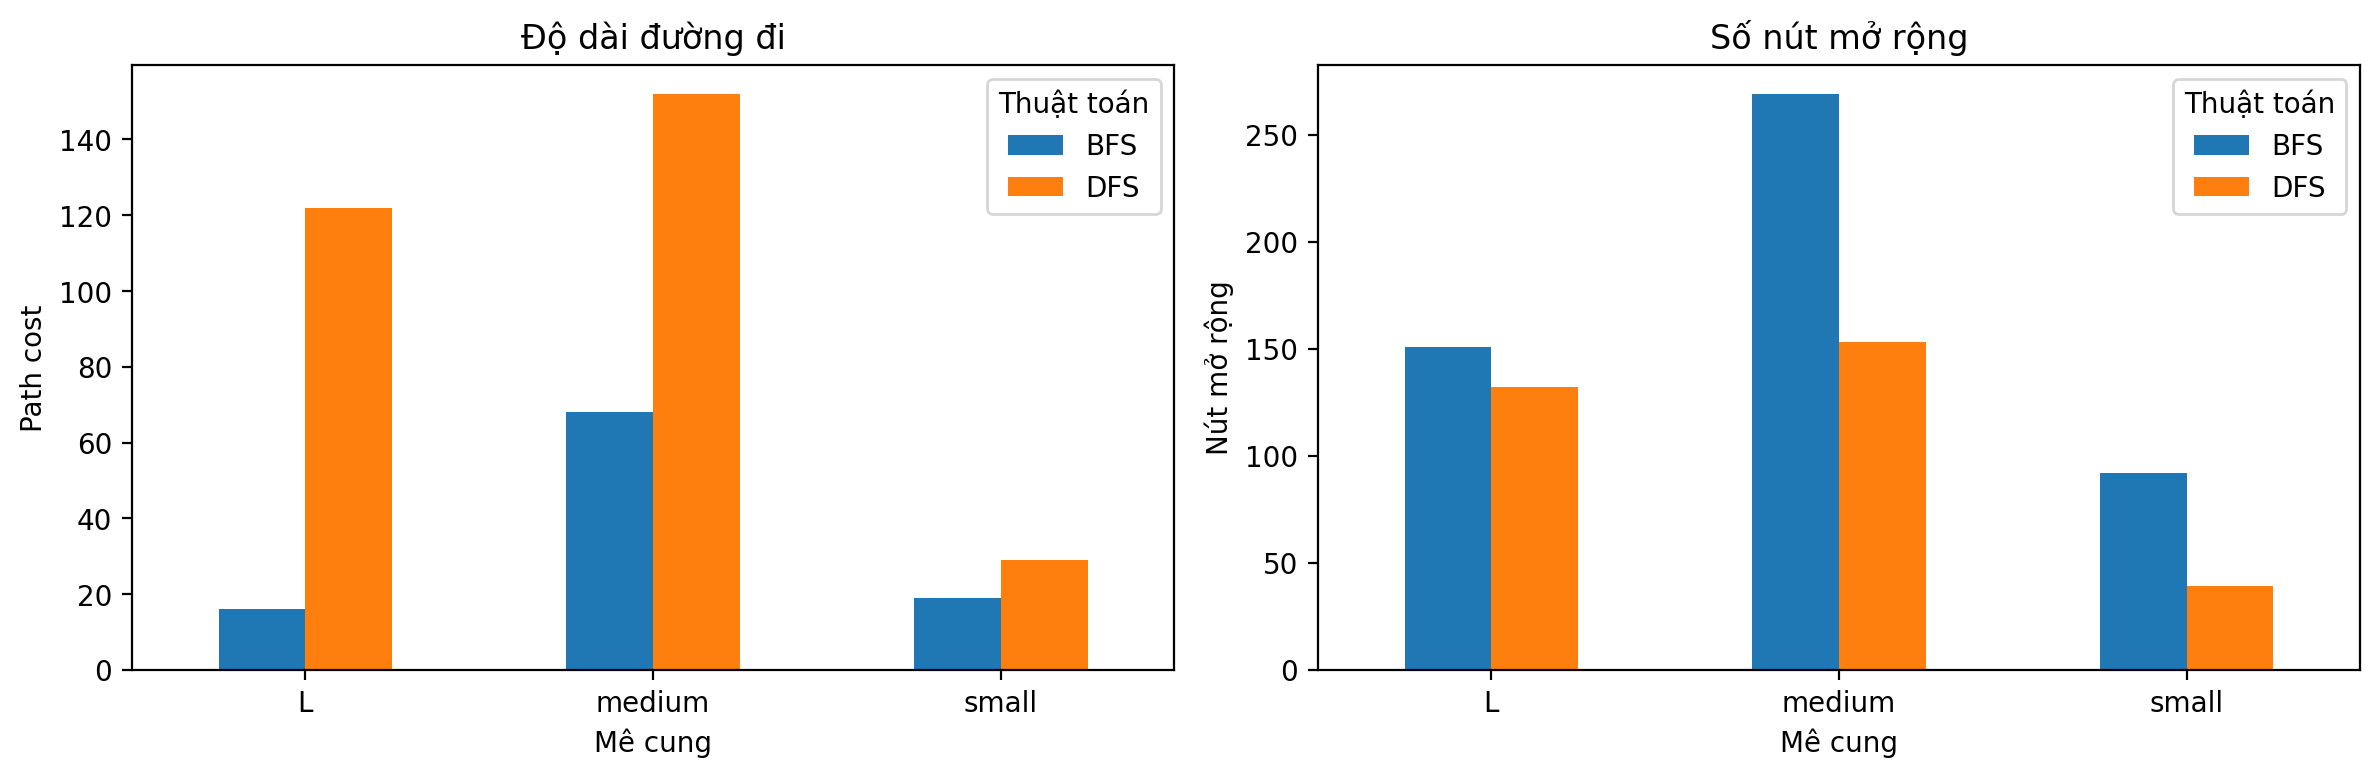

In [26]:
compare = []
for maze_name in ('small', 'medium', 'L'):
    with open(f'{maze_name}_maze.txt', encoding='utf-8') as f:
        maze_case = mh.parse_maze(f.read())
    ts.set_order('NESW')
    for algorithm in ('BFS', 'DFS'):
        r = (ts.best_first_search(maze_case, strategy='BFS') if algorithm == 'BFS'
             else ts.DFS(maze_case, check_cycle=True, max_tries=30000))
        compare.append({'Mê cung':maze_name, 'Thuật toán':algorithm,
                        'Path cost':r['path_cost'], 'Nút mở rộng':r['n_expanded'],
                        'Max frontier':r['max_frontier'], 'Max depth':r['max_depth'],
                        'Tìm được đường':r['path'] is not None})
compare_bai3 = pd.DataFrame(compare)
display(compare_bai3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, value, title in zip(axes, ('Path cost', 'Nút mở rộng'),
                            ('Độ dài đường đi', 'Số nút mở rộng')):
    pivot = compare_bai3.pivot(index='Mê cung', columns='Thuật toán', values=value)
    pivot.plot.bar(ax=ax, rot=0, title=title)
    ax.set_ylabel(value)
plt.tight_layout()
plt.show()

## 3.3. So sánh BFS và DFS về mặt lý thuyết

| Tiêu chí | BFS | DFS |
|---|---|---|
| Frontier | Queue — **FIFO** | Stack — **LIFO** |
| Quy tắc ưu tiên | Nút ở độ sâu nhỏ hơn được xét trước | Đi sâu vào một nhánh trước khi quay lui |
| Tính đầy đủ | Có khi hệ số phân nhánh hữu hạn và tồn tại lời giải ở độ sâu hữu hạn (với phát hiện trạng thái lặp phù hợp) | **Không bảo đảm** trong không gian vô hạn/có chu trình; với mê cung hữu hạn và kiểm tra chu trình đầy đủ, có thể tìm thấy lời giải nếu không cắt bởi `max_tries` |
| Tính tối ưu | Có khi mỗi bước chi phí bằng nhau | Không bảo đảm |
| Bộ nhớ | Có thể cần lưu nhiều nút của cùng một tầng; theo tree search thường $O(b^d)$ | DFS theo đường đi với cycle checking cần bộ nhớ theo độ sâu và số nhánh, thường khoảng $O(bm)$; kết quả phụ thuộc cách quản lý frontier |

Với $b$ là hệ số phân nhánh, $d$ là độ sâu lời giải nông nhất, $m$ là độ sâu tối đa của đường tìm kiếm. Độ phức tạp này là **ước lượng lý thuyết theo mô hình triển khai**, không phải số đo trực tiếp từ bảng thực nghiệm.

## 3.4. Nhận xét và kết luận

**Nhận xét kết quả:** Với `small_maze.txt`, BFS cho độ dài đường đi bằng **19 bước** (mỗi bước có chi phí 1). DFS với thứ tự hướng thêm `NESW` cho đường đi **29 bước**, vì thuật toán ưu tiên đi sâu và không bắt buộc phát hiện đường đi nông nhất trước. Khi thay đổi thứ tự sinh trạng thái con bằng cơ chế ngẫu nhiên, số nút mở rộng, độ dài đường đi và frontier cũng có thể thay đổi; kết quả cụ thể được ghi trong bảng thực nghiệm bên trên.

**Kết luận:** BFS phù hợp khi cần đường đi ngắn nhất trong lưới có chi phí bước đồng nhất, đổi lại có thể sử dụng nhiều bộ nhớ hơn. DFS thường tiết kiệm bộ nhớ hơn trong cách cài đặt theo đường đi, nhưng có thể tìm được lời giải dài và nhạy cảm với thứ tự sinh trạng thái con. Cần có kiểm tra chu trình và/hoặc giới hạn số lần mở rộng để tránh chạy quá lâu trên bài toán nhiều vòng lặp. Kết quả một số lần chạy DFS **không phải** bằng chứng rằng DFS luôn không tối ưu: điều quan trọng là DFS *không bảo đảm* tối ưu.

**Ghi chú:** Các con số ở mục trên được tính bởi bản cài đặt độc lập kèm theo, không được diễn giải là đầu ra gốc của `tree_search_solution.py` chưa được công bố.

---
# BÀI 4. DEPTH-LIMITED DFS (DLS) VÀ ITERATIVE DEEPENING SEARCH (IDS)

**Mục tiêu:** (1) Khảo sát DLS với các ngưỡng độ sâu khác nhau, (2) chạy IDS và đếm mỗi lần tăng ngưỡng, (3) giải thích tính chất của IDS so với DFS/BFS, (4) phân tích tác động của cycle checking.

**Xuất xứ mã nguồn:** Các phần trên được giữ nguyên từ bản notebook đã hoàn thiện Bài 3. Trong bản gốc, phần DLS và IDS gọi `ts.DFS(maze, limit=5, frontier_option=2)` và `ts.IDS(maze, frontier_option=2)`. Module `tree_search_solution.py` trong thư mục là bản **cài đặt độc lập để thực hành**, không phải mã nguồn không công bố của giảng viên. Vì API `ts.IDS()` không trả lại bảng ngưỡng lặp, phần dưới bổ sung `depth_limited_search_lab4()` và `iterative_deepening_search_lab4()` riêng nhằm ghi rõ các chỉ số theo từng vòng.

**Thiết lập:** `small_maze.txt`, chi phí bước bằng 1, thứ tự *đẩy nút vào stack* là `N,E,S,W` (do LIFO nên thứ tự mở rộng thực tế đảo lại khi có nhiều lựa chọn); cycle checking chỉ so sánh với các tổ tiên trên đường đi hiện tại. Dữ liệu mê cung không bị sửa trực tiếp.


## 4.1. Cơ sở lý thuyết

### Depth-Limited Search (DLS)

DLS là DFS có giới hạn độ sâu $L$. Tác tử không mở rộng các nút ở độ sâu $L$, nhưng **vẫn kiểm tra trạng thái đích ở mức này**. Kết quả có thể là:

- **FOUND:** tìm thấy đích trong phạm vi giới hạn.
- **CUTOFF:** chưa tìm được đích vì có nhánh bị chặn tại giới hạn $L$.
- **FAILURE:** không có lời giải trong không gian đang xét (không có nhánh nào bị cắt bởi $L$).

Với đường đi chi phí đơn vị, gọi $d$ là độ sâu tối ưu: $L<d$ không thể tìm thấy đích; $L=d$ có thể tìm được đích; $L>d$ có thể tìm được một đường đi dài hơn $d$ vì DLS vẫn tuân theo thứ tự DFS.

### Iterative Deepening Search (IDS)

IDS chạy DLS lặp với $L=0,1,2,\ldots$ cho đến khi tìm được đích. Với nghiệm tối ưu sâu $d$, IDS sử dụng **$d+1$ lần DLS** và tăng ngưỡng **$d$ lần** (nếu bắt đầu từ $0$).

Khi hệ số phân nhánh tối đa là $b>1$, DFS giới hạn độ sâu có bộ nhớ của frontier cỡ $O(bL)$; IDS dùng lại từng lần DLS nên có bộ nhớ cỡ $O(bd)$, thay vì phải giữ tất cả nút các tầng như BFS. Tổng lượng công việc có thể tăng do tìm lại các tầng nông nhưng vẫn thường ở bậc $O(b^d)$ trong bài toán cây phân nhánh đều. Điều này giả định không lưu tập `reached` toàn cục qua các lần lặp.


## 4.2. Cài đặt DLS dùng stack và cycle checking theo đường đi

Mỗi nút giữ vị trí, nút cha, hành động và độ sâu. Chỉ kiểm tra nút lặp trên *chuỗi tổ tiên hiện tại*, không đóng vĩnh viễn một trạng thái trên toàn bộ các đường đi. `expanded` đếm những nút thực sự được mở rộng (sinh trạng thái con), không tính nút đích hoặc nút bị chặn tại độ sâu giới hạn.


In [27]:
import tree_search_solution as ts
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Nạp lại mê cung để không phụ thuộc biến 'maze' đã thay đổi trong phần trên.
with open('small_maze.txt', encoding='utf-8') as fp:
    maze_bai4 = mh.parse_maze(fp.read())

ts.set_order('NESW')
bfs_reference_bai4 = ts.best_first_search(maze_bai4, strategy='BFS')
print('Độ dài lời giải BFS:', bfs_reference_bai4['path_cost'])
print('S =', mh.find_pos(maze_bai4, 'S'), '| G =', mh.find_pos(maze_bai4, 'G'))
from dataclasses import dataclass
from collections import deque
import maze_helper as mh
DIR={'N':(-1,0),'E':(0,1),'S':(1,0),'W':(0,-1)}
@dataclass(eq=False,slots=True)
class SearchNodeLab4:
 pos: tuple
 parent: object
 action: str | None
 depth: int

def successors_lab4(maze, pos, order='NESW'):
 for action in order:
  dr,dc=DIR[action]; nr,nc=pos[0]+dr,pos[1]+dc
  if 0 <= nr <maze.shape[0] and 0<=nc<maze.shape[1] and maze[nr,nc]!='X':
   yield action,(nr,nc)

def on_path_lab4(node,pos):
 while node is not None:
  if node.pos==pos:return True
  node=node.parent
 return False

def reconstruct_lab4(node):
 positions=[]; actions=[]
 while node is not None:
  positions.append(node.pos)
  if node.action is not None:actions.append(node.action)
  node=node.parent
 return positions[::-1], actions[::-1]

def depth_limited_search_lab4(maze,limit,order='NESW',max_expanded=250000):
 if limit<0:raise ValueError('limit must be nonnegative')
 start,goal=mh.find_pos(maze,'S'),mh.find_pos(maze,'G')
 stack=[SearchNodeLab4(start,None,None,0)]
 expanded=0; popped=0; max_frontier=1; max_depth=0; cutoff=False
 while stack:
  node=stack.pop();popped+=1; max_depth=max(max_depth,node.depth)
  if node.pos==goal:
   path,actions=reconstruct_lab4(node)
   return dict(status='FOUND',path=path,actions=actions,path_cost=node.depth,expanded=expanded,popped=popped,max_frontier=max_frontier,max_depth=max_depth)
  children=[(a,p) for a,p in successors_lab4(maze,node.pos,order) if not on_path_lab4(node,p)]
  if node.depth >= limit:
   cutoff = cutoff or bool(children)
   continue
  if expanded>=max_expanded:
   return dict(status='RESOURCE_LIMIT',path=None,actions=[],path_cost=None,expanded=expanded,popped=popped,max_frontier=max_frontier,max_depth=max_depth)
  expanded+=1
  for a,p in children:stack.append(SearchNodeLab4(p,node,a,node.depth+1))
  max_frontier=max(max_frontier,len(stack))
 return dict(status='CUTOFF' if cutoff else 'FAILURE',path=None,actions=[],path_cost=None,expanded=expanded,popped=popped,max_frontier=max_frontier,max_depth=max_depth)

def iterative_deepening_search_lab4(maze,order='NESW',max_limit=None,max_expanded_total=1000000):
 if max_limit is None: max_limit=int((maze!='X').sum())-1
 hist=[]; total=0; overall_frontier=0
 for limit in range(max_limit+1):
  r=depth_limited_search_lab4(maze,limit,order,max_expanded=max_expanded_total-total)
  total+=r['expanded'];overall_frontier=max(overall_frontier,r['max_frontier'])
  hist.append(dict(limit=limit,status=r['status'],expanded=r['expanded'],total=total,max_frontier=r['max_frontier']))
  if r['status'] != 'CUTOFF':
   return dict(**r,history=hist,total_expanded=total,max_frontier_across_runs=overall_frontier,increments=limit,iterations=len(hist))
 raise RuntimeError('maximum limit reached without conclusion')


Độ dài lời giải BFS: 19
S = (np.int64(3), np.int64(11)) | G = (np.int64(8), np.int64(1))


## 4.3. Thí nghiệm thay đổi giới hạn DLS

Lần lượt thử $L=0,5,10,18,19,20,30$. Giới hạn 18 nằm ngay dưới độ sâu nghiệm tối ưu, giới hạn 19 bằng độ sâu tối ưu, còn 30 lớn hơn rõ rệt để khảo sát tính không tối ưu của DFS.


In [28]:
limits_bai4 = [0, 5, 10, 18, 19, 20, 30]
rows_dls_bai4 = []
results_dls_bai4 = {}
for L in limits_bai4:
    result_dls = depth_limited_search_lab4(maze_bai4, L, order='NESW')
    results_dls_bai4[L] = result_dls
    rows_dls_bai4.append({
        'L (giới hạn)': L,
        'Trạng thái': result_dls['status'],
        'Path cost': result_dls['path_cost'],
        'Nút mở rộng': result_dls['expanded'],
        'Max frontier': result_dls['max_frontier'],
        'Độ sâu tối đa đã duyệt': result_dls['max_depth']
    })
dls_table_bai4 = pd.DataFrame(rows_dls_bai4)
display(dls_table_bai4)
assert results_dls_bai4[18]['status'] == 'CUTOFF'
assert results_dls_bai4[19]['path_cost'] == bfs_reference_bai4['path_cost'] == 19
assert results_dls_bai4[30]['path_cost'] > bfs_reference_bai4['path_cost']


,L (giới hạn),Trạng thái,Path cost,Nút mở rộng,Max frontier,Độ sâu tối đa đã duyệt
0,0,CUTOFF,NaN,0,1,0
1,5,CUTOFF,NaN,15,4,5
2,10,CUTOFF,NaN,44,5,10
3,18,CUTOFF,NaN,114,6,18
4,19,FOUND,19.0,72,6,19
5,20,FOUND,19.0,79,6,20
6,30,FOUND,29.0,39,5,29


**Nhận xét:** Với `small_maze`, $L=18$ cho kết quả `CUTOFF`, $L=19$ tìm được đường đi dài 19 bước (bằng BFS). Tuy nhiên, khi $L=30$, DLS có thể trả về đường dài 29 bước do ưu tiên duyệt sâu theo thứ tự stack, minh họa rằng giới hạn lớn hơn $d$ không buộc DFS tối ưu.


DLS, L=19: cost=19, steps=19, expanded=72


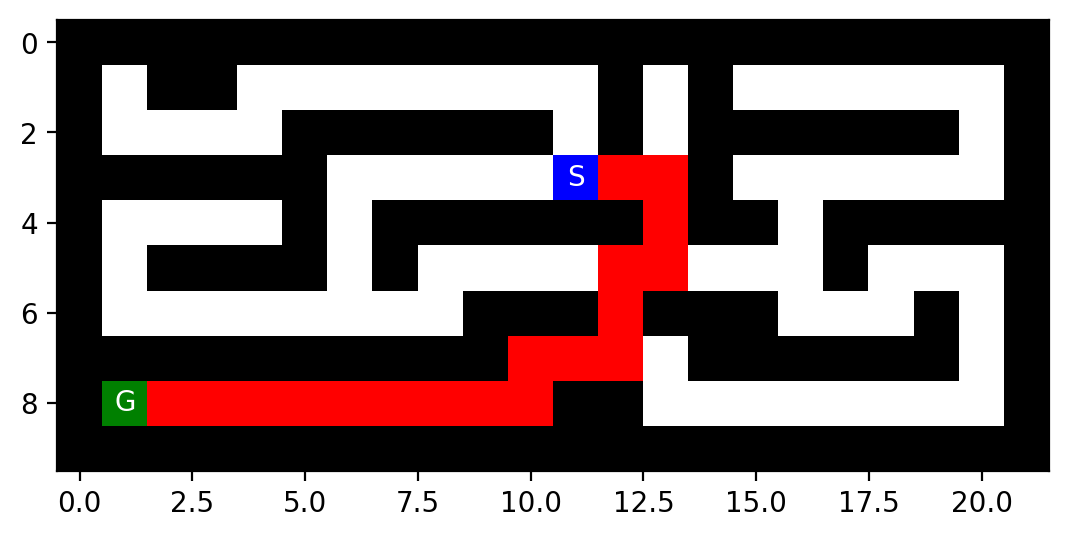

DLS, L=30: cost=29, steps=29, expanded=39


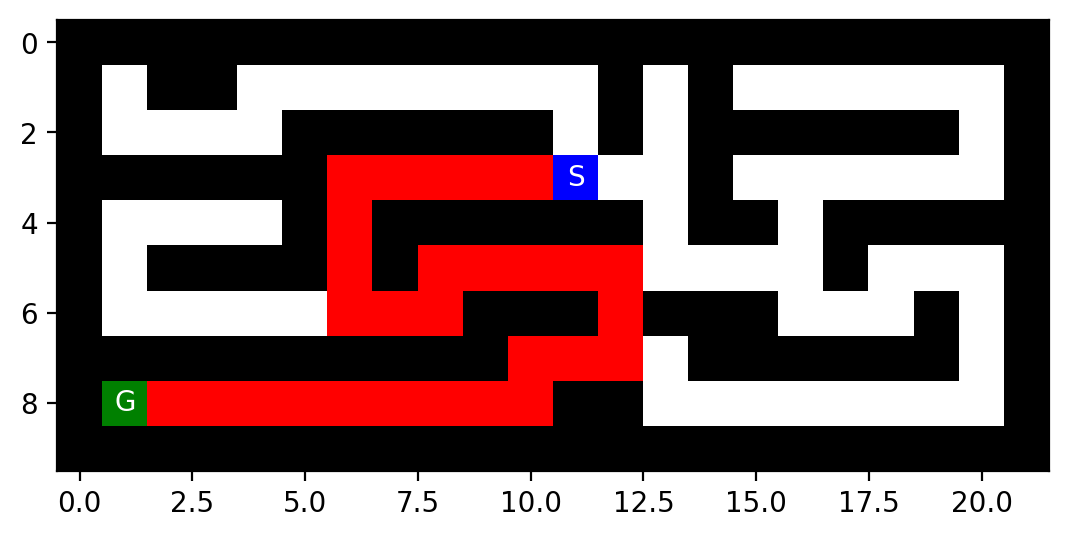

In [29]:
# Vẽ đường đi trên bản sao của mê cung: DLS với giới hạn tối ưu và giới hạn lớn.
def show_lab4_path(maze, result, label):
    if result['path'] is None:
        print(label, ': chưa có đường đi')
        return
    annotated = np.copy(maze)
    for pos in result['path'][1:-1]:
        if annotated[pos] == ' ':
            annotated[pos] = 'P'
    print(f"{label}: cost={result['path_cost']}, steps={len(result['actions'])}, "
          f"expanded={result['expanded']}")
    mh.show_maze(annotated)

show_lab4_path(maze_bai4, results_dls_bai4[19], 'DLS, L=19')
show_lab4_path(maze_bai4, results_dls_bai4[30], 'DLS, L=30')


## 4.4. IDS — theo dõi từng ngưỡng từ 0 đến khi tìm được lời giải

`iterative_deepening_search_lab4()` gọi lại DLS hoàn toàn độc lập sau mỗi lần tăng giới hạn. Bảng sau ghi mức $L$, trạng thái, số nút mở rộng trong lần DLS đó, số mở rộng cộng dồn và `max_frontier`. Tổng mở rộng của IDS là tổng giữa tất cả các lần DLS, không phải chỉ số riêng của vòng cuối.


In [30]:
ids_bai4 = iterative_deepening_search_lab4(maze_bai4, order='NESW')
ids_table_bai4 = pd.DataFrame(ids_bai4['history']).rename(columns={
    'limit': 'Giới hạn L', 'status': 'Kết quả',
    'expanded': 'Nút mở rộng / lượt',
    'total': 'Nút mở rộng cộng dồn',
    'max_frontier': 'Max frontier / lượt'
})
display(ids_table_bai4)
print('Trạng thái IDS:', ids_bai4['status'])
print('Số vòng chạy DLS:', ids_bai4['iterations'])
print('Số lần tăng giới hạn:', ids_bai4['increments'])
print('Chi phí đường đi:', ids_bai4['path_cost'])
print('Tổng nút mở rộng:', ids_bai4['total_expanded'])
print('Max frontier của IDS:', ids_bai4['max_frontier_across_runs'])
assert ids_bai4['iterations'] == 20
assert ids_bai4['increments'] == 19
assert ids_bai4['path_cost'] == bfs_reference_bai4['path_cost']

# Đối chiếu kết quả đích với API IDS hiện có ở bài mẫu.
ts.set_order('NESW')
ids_module_bai4 = ts.IDS(maze_bai4, frontier_option=2, max_tries=100000)
print('IDS từ module hỗ trợ: path cost =', ids_module_bai4['path_cost'])
assert ids_module_bai4['path_cost'] == ids_bai4['path_cost']


,Giới hạn L,Kết quả,Nút mở rộng / lượt,Nút mở rộng cộng dồn,Max frontier / lượt
0,0,CUTOFF,0,0,1
1,1,CUTOFF,1,1,3
2,2,CUTOFF,4,5,3
3,3,CUTOFF,7,12,3
4,4,CUTOFF,11,23,3
5,5,CUTOFF,15,38,4
6,6,CUTOFF,19,57,5
7,7,CUTOFF,24,81,5
8,8,CUTOFF,29,110,5
9,9,CUTOFF,36,146,5


Trạng thái IDS: FOUND
Số vòng chạy DLS: 20
Số lần tăng giới hạn: 19
Chi phí đường đi: 19
Tổng nút mở rộng: 923
Max frontier của IDS: 6
IDS từ module hỗ trợ: path cost = 19


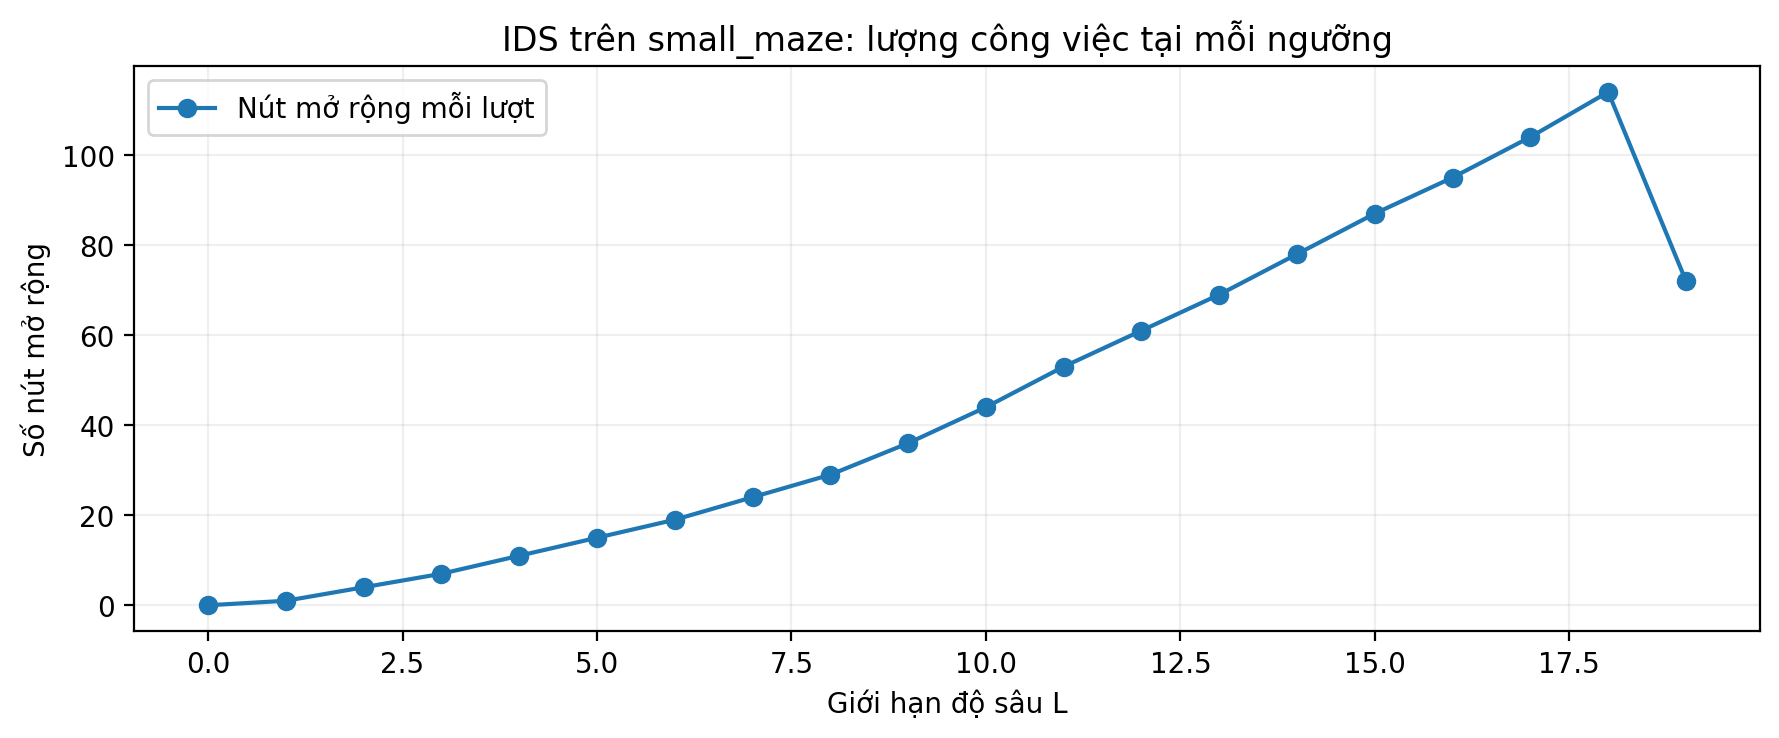

IDS (đường đi cuối cùng): cost=19, steps=19, expanded=72


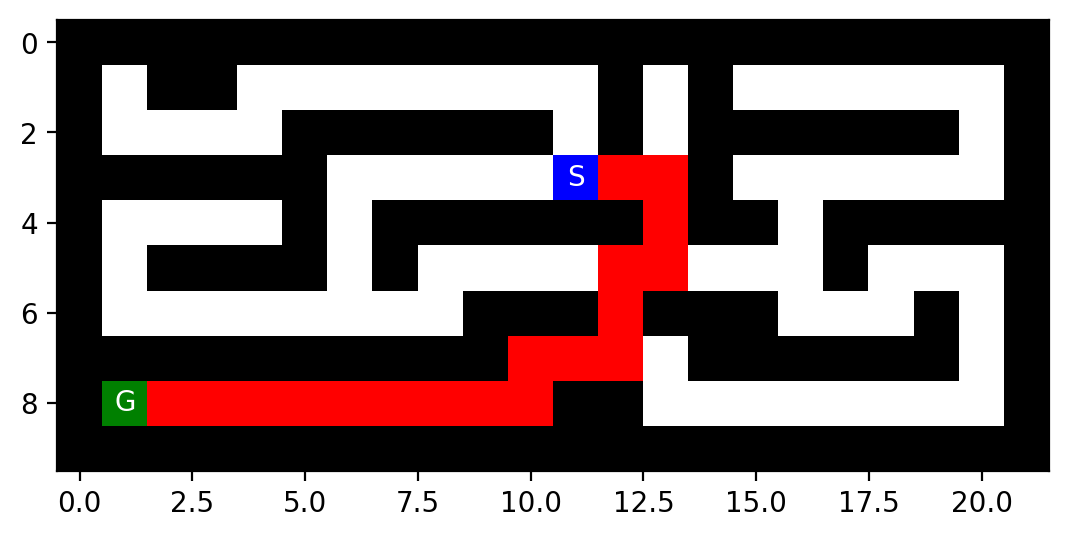

In [31]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(ids_table_bai4['Giới hạn L'], ids_table_bai4['Nút mở rộng / lượt'], marker='o', label='Nút mở rộng mỗi lượt')
ax.set_xlabel('Giới hạn độ sâu L')
ax.set_ylabel('Số nút mở rộng')
ax.set_title('IDS trên small_maze: lượng công việc tại mỗi ngưỡng')
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()
show_lab4_path(maze_bai4, ids_bai4, 'IDS (đường đi cuối cùng)')


### Nhận xét về tính đầy đủ, tối ưu và bộ nhớ

- **Tính đầy đủ:** Trên không gian trạng thái có hệ số phân nhánh hữu hạn và tồn tại lời giải ở độ sâu hữu hạn, IDS lần lượt mở rộng giới hạn cho đến khi đủ sâu để tìm lời giải, với điều kiện mỗi DLS hoạt động đúng.
- **Tính tối ưu:** Khi mọi hành động có chi phí bằng nhau, IDS tìm được lời giải ở **ngưỡng nhỏ nhất cho phép đạt đích**; do đó số bước bằng nghiệm ngắn nhất của BFS. Trong bài thực nghiệm, `small_maze` có $d=19$, IDS đạt đích ở $L=19$.
- **Bộ nhớ:** Mỗi lần DLS kết thúc là stack được giải phóng và tạo lại ở giới hạn tiếp theo. IDS có thể lưu ít phần tử frontier hơn BFS; đổi lại phải duyệt lặp các tầng nông. Không nhầm `max_frontier` (số mục của stack) với toàn bộ bộ nhớ Python được sử dụng.
- **Số lần lặp:** Đặt $L=0,1,2,...,19$ tương ứng **20 lượt DLS**, tức **19 lần tăng giới hạn**.

**Lưu ý kỹ thuật:** Thực hiện chỉ so sánh tổ tiên có thể lặp lại cùng một trạng thái trong các nhánh khác nhau. Khi bộ nhớ tìm kiếm không lưu `reached` toàn cục, các vùng đã đến thường không được tô như BFS (đúng với ghi chú của notebook gốc). Cách cycle checking có thể ảnh hưởng thời gian chạy hoặc tính đầy đủ của DLS/IDS.


## 4.5. Minh họa lỗi khi kiểm tra chu trình không phù hợp

Giả sử dùng một tập `visited` toàn cục cho DLS và đưa trạng thái vào tập ngay khi **sinh nút con**. Một trạng thái có thể được đưa vào stack lần đầu qua đường đi sâu và bị chặn bởi giới hạn, rồi đường đi ngắn hơn đến chính trạng thái đó bị loại vì đã nằm trong `visited`. Kết quả có thể bỏ sót lời giải dù giới hạn đã đủ. Dưới đây là phản ví dụ trên chính `small_maze`.


In [32]:
def unsafe_global_visited_dls_lab4(maze, limit, order='NESW'):
    """Chỉ để minh họa sai lầm; KHÔNG dùng cách này để cài IDS."""
    start, goal = mh.find_pos(maze, 'S'), mh.find_pos(maze, 'G')
    stack = [SearchNodeLab4(start, None, None, 0)]
    visited = {start}
    popped = 0
    while stack:
        node = stack.pop()
        popped += 1
        if node.pos == goal:
            path, actions = reconstruct_lab4(node)
            return {'status': 'FOUND', 'path_cost': node.depth, 'popped': popped}
        if node.depth >= limit:
            continue
        for action, pos in successors_lab4(maze, node.pos, order):
            if pos in visited:
                continue  # SAI: có thể loại bỏ đường tới cùng vị trí với độ sâu nhỏ hơn
            visited.add(pos)
            stack.append(SearchNodeLab4(pos, node, action, node.depth + 1))
    return {'status': 'NO_SOLUTION', 'path_cost': None, 'popped': popped}

correct_bai4 = depth_limited_search_lab4(maze_bai4, 19, order='NESW')
incorrect_bai4 = unsafe_global_visited_dls_lab4(maze_bai4, 19, order='NESW')
print('Cycle checking theo đường đi:', correct_bai4['status'], 'cost =', correct_bai4['path_cost'])
print('Cycle checking sai (visited toàn cục):', incorrect_bai4['status'], 'cost =', incorrect_bai4['path_cost'])
assert correct_bai4['status'] == 'FOUND'
assert incorrect_bai4['status'] == 'NO_SOLUTION'


Cycle checking theo đường đi: FOUND cost = 19
Cycle checking sai (visited toàn cục): NO_SOLUTION cost = None


## 4.6. Khảo sát bổ sung trên `medium_maze`

Để bảo đảm kết luận không chỉ phụ thuộc một mê cung, ta kiểm chứng rằng số lần tăng ngưỡng của IDS bằng độ sâu nghiệm tối ưu trên `medium_maze`. Ví dụ này sử dụng **cùng thứ tự cố định `NESW`** và kiểm tra chu trình theo đường đi; không dùng `visited` toàn cục để cắt bỏ trạng thái.


In [33]:
with open('medium_maze.txt', encoding='utf-8') as fp:
    medium_bai4 = mh.parse_maze(fp.read())
ts.set_order('NESW')
bfs_medium_bai4 = ts.best_first_search(medium_bai4, strategy='BFS')
ids_medium_bai4 = iterative_deepening_search_lab4(medium_bai4, order='NESW')
print('medium_maze — BFS shortest path:', bfs_medium_bai4['path_cost'])
print('medium_maze — IDS path cost:', ids_medium_bai4['path_cost'])
print('medium_maze — tăng giới hạn:', ids_medium_bai4['increments'])
print('medium_maze — tổng số nút mở rộng IDS:', ids_medium_bai4['total_expanded'])
print('medium_maze — Max frontier IDS:', ids_medium_bai4['max_frontier_across_runs'])
assert bfs_medium_bai4['path_cost'] == ids_medium_bai4['path_cost'] == 68


medium_maze — BFS shortest path: 68
medium_maze — IDS path cost: 68
medium_maze — tăng giới hạn: 68
medium_maze — tổng số nút mở rộng IDS: 15665
medium_maze — Max frontier IDS: 8


## 4.7. So sánh DLS và IDS

| Tiêu chí | DLS | IDS |
|---|---|---|
| Frontier | Stack (LIFO) | Stack (LIFO) được tạo lại sau mỗi giới hạn |
| Giới hạn | Cố định $L$ | Tăng dần $L=0,1,2,\ldots$ |
| Tính đầy đủ | Không nếu $L<d$ | Có với độ sâu nghiệm hữu hạn, branching hữu hạn và DLS đúng |
| Tính tối ưu (chi phí đơn vị) | Không bảo đảm nếu $L>d$ | Có, đạt đích tại độ sâu lời giải nhỏ nhất |
| Bộ nhớ (tree-search) | $O(bL)$ | $O(bd)$, khi không giữ `reached` toàn cục |
| Chi phí thời gian | Phụ thuộc $L$, nhánh và thứ tự | Duyệt lại tầng nông nhiều lần |

### Kết luận

Thí nghiệm cho thấy **DLS** giúp tránh tìm kiếm vô hạn bằng việc cắt các nhánh tại một độ sâu quy định, nhưng nếu $L$ quá nhỏ sẽ không tìm được đường đi, còn nếu $L$ quá lớn thì lời giải có thể không ngắn nhất. **IDS** khắc phục khó khăn chọn giới hạn bằng cách tăng $L$ lần lượt, vì vậy có thể tìm ra lời giải có độ sâu tối ưu mà không cần giữ toàn bộ frontier của BFS. Trên `small_maze`, IDS tăng giới hạn **19 lần**, chạy **20 lượt DLS** rồi tìm ra đường đi **19 bước**, trùng chi phí tối ưu của BFS. Ví dụ cycle checking sai với `visited` toàn cục chứng minh IDS chỉ hoạt động đáng tin cậy khi DLS thành phần được triển khai phù hợp.

**Phạm vi kết luận:** Các giá trị số đo trong Bài 4 thuộc bản cài đặt độc lập kèm notebook và thứ tự mở rộng `NESW`; số nút mở rộng có thể khác nếu dùng phiên bản gốc chưa công bố hoặc chọn thứ tự ngẫu nhiên.


---
# BÀI 5. TÌM KIẾM CÓ THÔNG TIN: GBFS, A* VÀ WEIGHTED A*

**Mục tiêu thực hành:** (1) chạy GBFS, A*, Weighted A* trong `02_Maze_Example.ipynb`; (2) dùng `04_Maze_BFS_vs_A_Star.ipynb` để đối chiếu BFS và A*; (3) so sánh Euclidean và Manhattan; (4) thay đổi trọng số $w$ để quan sát đánh đổi số nút mở rộng và chất lượng đường đi.

Phần thực hành này được **bổ sung** sau các cell gốc và Bài 3–4, không thay thế các thuật toán cũ. Vì mã nguồn `tree_search_solution.py` của giảng viên được ghi rõ là *không công bố*, ta sử dụng phiên bản triển khai học tập tương thích đã đi kèm bộ bài trước. Phần đo lường dưới đây áp dụng cho phiên bản hỗ trợ đó, không mặc định đồng nhất với kết quả của tác giả.

**Thiết lập công bằng:** di chuyển bốn hướng N–E–S–W, chi phí mỗi bước là 1, thứ tự sinh trạng thái cố định `NESW`. Một **nút mở rộng** được tính khi được lấy khỏi frontier để sinh các nút kế tiếp (không tính nút đích khi vừa được lấy ra). `max_frontier` là số phần tử lớn nhất từng có trong frontier. Dùng cùng một mê cung/giả định cho mọi thuật toán.

## 5.1. Nguyên lý ba chiến lược tìm kiếm có thông tin

Đặt $s$ là một trạng thái, $s_g$ là trạng thái đích. Với đường đi trên lưới gồm bốn hướng:

- Manhattan: $h_M(s)=|r_s-r_g|+|c_s-c_g|$.
- Euclidean: $h_E(s)=\sqrt{(r_s-r_g)^2+(c_s-c_g)^2}$.
- GBFS: chọn nút có **$h(s)$ nhỏ nhất**; không xét chi phí đã đi nên không bảo đảm đường đi tối ưu.
- A*: chọn nút có **$f(s)=g(s)+h(s)$ nhỏ nhất**. Ở bài toán này, cả Manhattan và Euclidean đều là heuristic *admissible* và *consistent* với chi phí bước bằng 1; A* với quản lý chi phí tốt nhất cho trạng thái có thể tìm đường tối ưu.
- Weighted A*: chọn nút có **$f_w(s)=g(s)+w h(s)$ nhỏ nhất**. $w=1$ chính là A*. Khi $w>1$, khả năng tìm kiếm được định hướng theo heuristic mạnh hơn, nhưng có thể mất tính tối ưu.

**Chú ý:** Giá trị $h$ là ước lượng trực tiếp tới đích, *không tính tường*. Do đó giá trị nhỏ hơn không đồng nghĩa đường đi thực tế ngắn hơn. Euclidean $\leq$ Manhattan cho mọi vị trí trên lưới này.

In [34]:
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import maze_helper as mh
import tree_search_solution as ts
from IPython.display import display

# Mỗi lượt đo nạp lại dữ liệu và cố định thứ tự hướng; không dùng biến 'maze' từ cell cũ.
def load_maze_bai5(name):
    with open(f'{name}_maze.txt', encoding='utf-8') as f:
        return mh.parse_maze(f.read())

# Hai heuristic (nhất quán với cách gọi ts.heuristic trong notebook gốc)
def h_manhattan_bai5(pos, goal):
    return abs(pos[0] - goal[0]) + abs(pos[1] - goal[1])

def h_euclidean_bai5(pos, goal):
    return math.hypot(pos[0] - goal[0], pos[1] - goal[1])

assert h_manhattan_bai5((1, 1), (4, 5)) == 7
assert h_euclidean_bai5((1, 1), (4, 5)) == 5.0

# Trả về kết quả và thời gian mỗi lần chạy; không làm thay đổi dữ liệu mê cung.
def run_search_bai5(maze, algorithm, heuristic='Manhattan', weight=1.0):
    ts.set_order('NESW')
    ts.heuristic = h_manhattan_bai5 if heuristic == 'Manhattan' else h_euclidean_bai5
    strategy = 'A*' if algorithm == 'Weighted A*' else algorithm
    t0 = time.perf_counter()
    result = ts.best_first_search(maze, strategy=strategy, W=weight,
                                  debug=False, vis=False, animation=False)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    return result, elapsed_ms

maze_small_bai5 = load_maze_bai5('small')
print('Trạng thái S:', mh.find_pos(maze_small_bai5, 'S'),
      '| G:', mh.find_pos(maze_small_bai5, 'G'))

Trạng thái S: (np.int64(3), np.int64(11)) | G: (np.int64(8), np.int64(1))


## 5.2. Chạy GBFS, A* (hai heuristic) và so sánh với BFS

Đầu tiên kiểm tra trên `small_maze`: BFS là thuật toán không thông tin đóng vai trò tham chiếu cho độ dài tối ưu; GBFS chỉ xem $h$; A* xét đồng thời $g$ và $h$. Hai lần chạy A* chỉ thay heuristic, giữ nguyên các tham số khác.

In [35]:
settings_small_bai5 = [
    ('BFS', 'Manhattan', 1.0),
    ('GBFS', 'Manhattan', 1.0),
    ('A*', 'Euclidean', 1.0),
    ('A*', 'Manhattan', 1.0),
    ('Weighted A*', 'Manhattan', 5.0),
]
rows_small_bai5 = []
results_small_bai5 = {}
for algorithm, heur, w in settings_small_bai5:
    result, elapsed = run_search_bai5(maze_small_bai5, algorithm, heur, w)
    key = f'{algorithm} / {heur}' + (f' / w={w:g}' if algorithm == 'Weighted A*' else '')
    results_small_bai5[key] = result
    rows_small_bai5.append({
        'Thuật toán / heuristic': key,
        'Path cost': result['path_cost'],
        'Nút mở rộng': result['n_expanded'],
        'Max frontier': result['max_frontier'],
        'Thời gian (ms)': round(elapsed, 4),
    })
table_small_bai5 = pd.DataFrame(rows_small_bai5)
display(table_small_bai5)
assert results_small_bai5['BFS / Manhattan']['path_cost'] == 19
assert results_small_bai5['A* / Euclidean']['path_cost'] == 19
assert results_small_bai5['A* / Manhattan']['path_cost'] == 19

,Thuật toán / heuristic,Path cost,Nút mở rộng,Max frontier,Thời gian (ms)
0,BFS / Manhattan,19,92,9,0.4282
1,GBFS / Manhattan,29,39,5,0.4435
2,A* / Euclidean,19,55,7,0.4186
3,A* / Manhattan,19,51,7,0.4582
4,Weighted A* / Manhattan / w=5,29,41,5,0.2960


### Phân tích kết quả `small_maze`

- BFS không có heuristic nhưng đảm bảo lời giải ngắn nhất khi chi phí bước đồng đều.
- GBFS ưu tiên ô gần đích theo Manhattan nhưng có thể đi vòng và trả về đường dài hơn BFS.
- A* với Manhattan/Euclidean sử dụng $g+h$, nên vừa hướng tới đích vừa cân nhắc chi phí đã đi.
- So sánh số nút mở rộng thay vì chỉ thời gian: thời gian bị ảnh hưởng bởi hệ điều hành, môi trường Python và lần chạy. Chỉ nên diễn giải tốc độ từ các phép đo lặp lại.

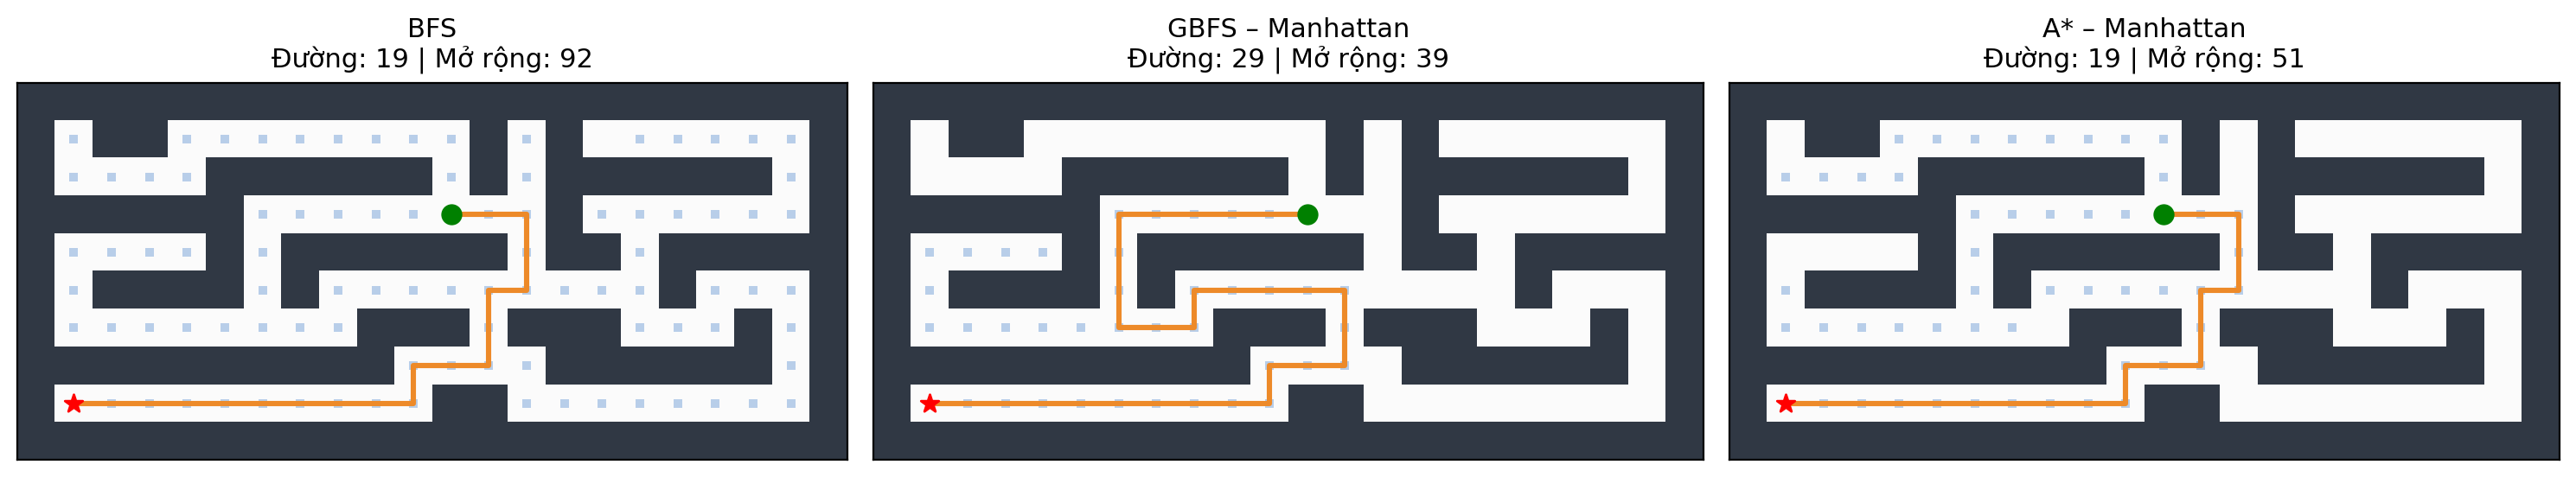

In [36]:
# Trực quan hóa đường đi (cột) và vùng trạng thái đã mở rộng (chấm xanh nhạt).
# Các hình được tạo từ kết quả thực, không thay đổi dữ liệu gốc.
from matplotlib.colors import ListedColormap

def plot_search_bai5(ax, maze, result, title):
    walkable = (maze != 'X').astype(float)
    ax.imshow(walkable, cmap=ListedColormap(['#303844', '#fbfbfb']), vmin=0, vmax=1)
    for r, c in result['reached']:
        if maze[r, c] == ' ':
            ax.scatter(c, r, s=15, c='#77a2d9', alpha=0.50, marker='s', linewidths=0)
    if result['path']:
        xx = [p[1] for p in result['path']]
        yy = [p[0] for p in result['path']]
        ax.plot(xx, yy, color='#ed8a29', lw=2.2)
    start = mh.find_pos(maze, 'S')
    goal = mh.find_pos(maze, 'G')
    ax.scatter([start[1]], [start[0]], c='green', s=60, zorder=5, marker='o')
    ax.scatter([goal[1]], [goal[0]], c='red', s=60, zorder=5, marker='*')
    ax.set_title(title, fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
for ax, key, name in zip(axes,
    ('BFS / Manhattan', 'GBFS / Manhattan', 'A* / Manhattan'),
    ('BFS', 'GBFS – Manhattan', 'A* – Manhattan')):
    res = results_small_bai5[key]
    plot_search_bai5(ax, maze_small_bai5, res,
                     f'{name}\nĐường: {res["path_cost"]} | Mở rộng: {res["n_expanded"]}')
plt.tight_layout()
plt.show()

## 5.3. Khảo sát A*: Manhattan so với Euclidean trên nhiều mê cung

Giữ cố định `strategy="A*"`, $w=1$ và thứ tự sinh `NESW`, thay hai heuristic trên `small`, `medium`, `L`, `open`. So sánh với BFS trên **cùng mê cung** để kiểm chứng độ dài tối ưu và vùng tìm kiếm. Với lưới 4 hướng và mỗi bước chi phí 1, Manhattan thường hướng dẫn mạnh hơn Euclidean, nhưng số nút thực tế có thể khác nhau tùy mê cung và cách xử lý hòa điểm.

In [37]:
rows_compare_bai5 = []
for name in ('small', 'medium', 'L', 'open'):
    maze_case = load_maze_bai5(name)
    for algorithm, heur in [('BFS', 'Manhattan'),
                             ('A*', 'Euclidean'), ('A*', 'Manhattan')]:
        res, elapsed = run_search_bai5(maze_case, algorithm, heur)
        rows_compare_bai5.append({
            'Mê cung': name, 'Thuật toán': algorithm, 'Heuristic': heur if algorithm=='A*' else '—',
            'Path cost': res['path_cost'], 'Nút mở rộng': res['n_expanded'],
            'Max frontier': res['max_frontier'], 'Thời gian (ms)': round(elapsed, 4)
        })
compare_bai5 = pd.DataFrame(rows_compare_bai5)
display(compare_bai5)
for name in ('small','medium','L','open'):
    block = compare_bai5[compare_bai5['Mê cung'] == name]
    assert block['Path cost'].notna().all()
    assert block['Path cost'].nunique() == 1, f'A* path differs from BFS on {name}'

,Mê cung,Thuật toán,Heuristic,Path cost,Nút mở rộng,Max frontier,Thời gian (ms)
0,small,BFS,—,19,92,9,0.5546
1,small,A*,Euclidean,19,55,7,0.3223
2,small,A*,Manhattan,19,51,7,0.4043
3,medium,BFS,—,68,269,9,1.0895
4,medium,A*,Euclidean,68,224,8,1.1296
5,medium,A*,Manhattan,68,217,8,1.8114
6,L,BFS,—,16,151,17,0.6981
7,L,A*,Euclidean,16,62,27,0.3743
8,L,A*,Manhattan,16,40,29,0.4709
9,open,BFS,—,54,682,25,3.2472


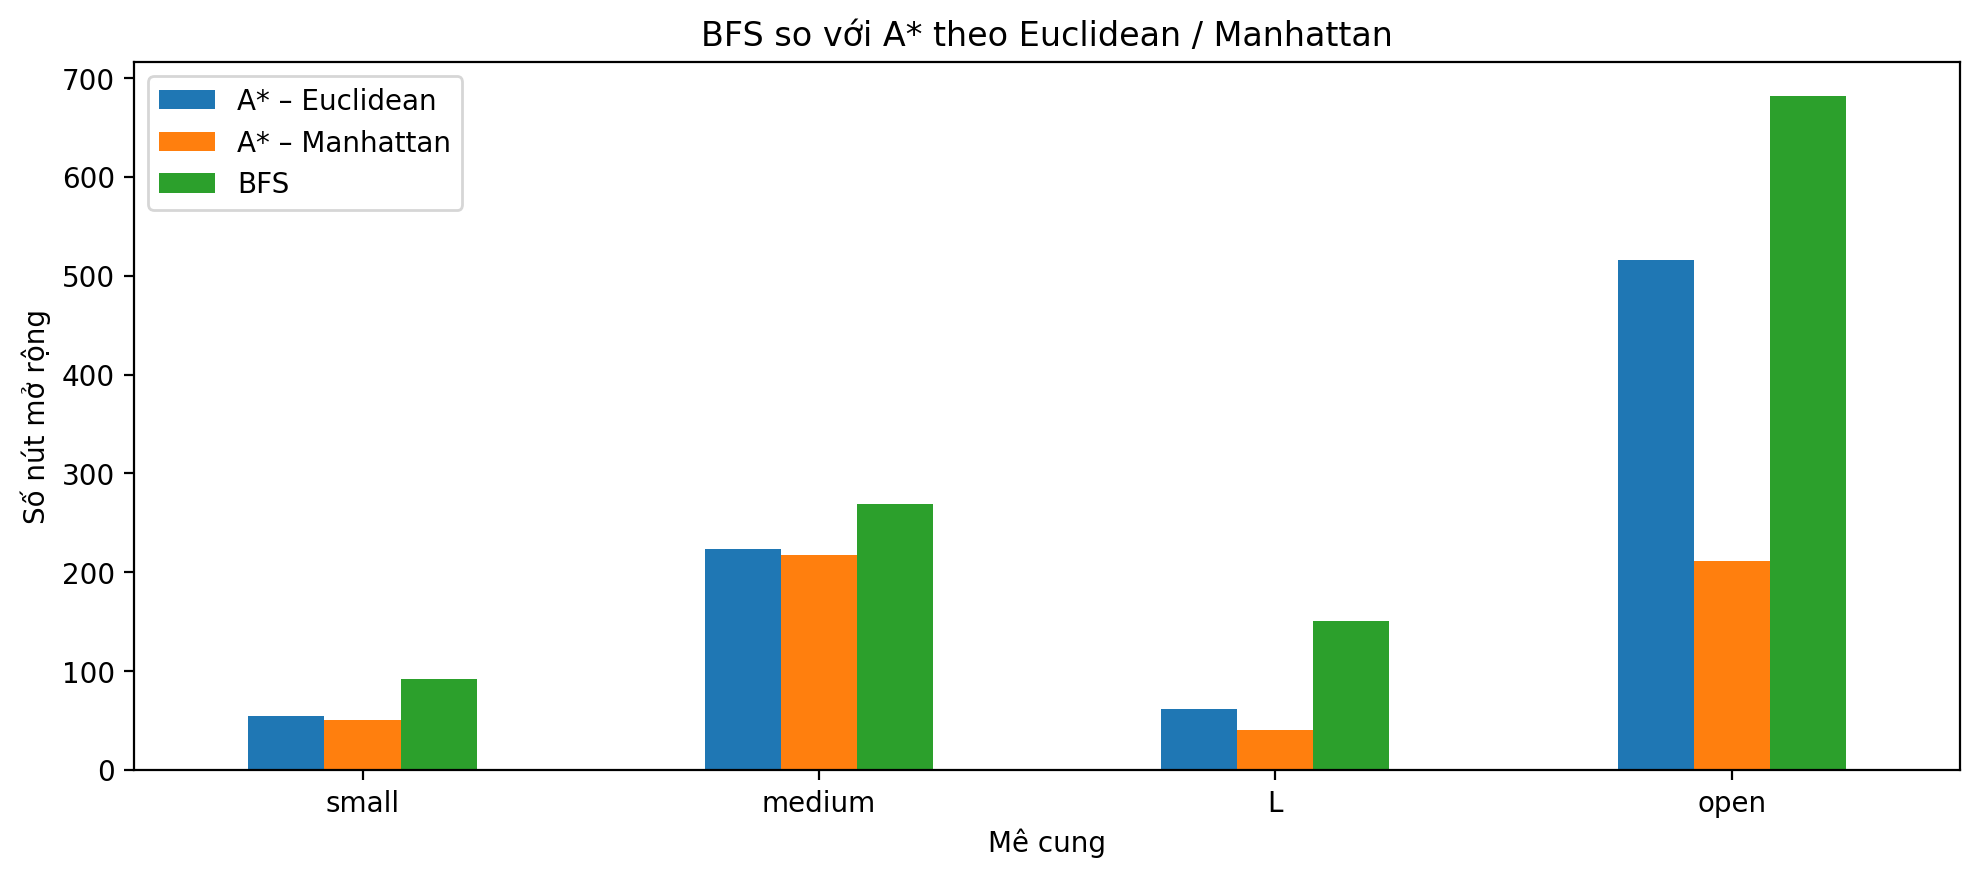

In [38]:
# Hiển thị số nút mở rộng giữa BFS và A* theo heuristic trên các mê cung.
plot_data = compare_bai5.copy()
plot_data['Phương pháp'] = plot_data.apply(
    lambda r: 'BFS' if r['Thuật toán']=='BFS' else 'A* – '+r['Heuristic'], axis=1)
ax = (plot_data.pivot(index='Mê cung', columns='Phương pháp', values='Nút mở rộng')
      .reindex(['small', 'medium', 'L', 'open'])
      .plot(kind='bar', figsize=(10, 4.5), rot=0))
ax.set_ylabel('Số nút mở rộng')
ax.set_title('BFS so với A* theo Euclidean / Manhattan')
ax.legend(loc='best')
plt.tight_layout()
plt.show()

## 5.4. Weighted A*: thay trọng số $w$ và đánh giá đánh đổi

Xét $f_w(n)=g(n)+w\,h_M(n)$; thay $w \in \{0.5, 1, 1.5, 2, 3, 5, 10\}$ trên **cùng** `small_maze`, ghi các chỉ số: path cost, số nút mở rộng, max frontier, thời gian. Dùng $w=1$ làm đường cơ sở A*; giá trị $w>1$ có thể tạo đường dài hơn dù có trường hợp giảm công tìm kiếm. Không kết luận tăng $w$ thì *luôn* giảm số nút hoặc thời gian.

Ở lưới 4 hướng, cả hai heuristic đều admissible/consistent, nhưng với $w>1$, $w h(n)$ có thể đánh giá cao hơn chi phí còn lại nên **không còn bảo đảm tìm đường tối ưu**. Với $0 \leq w \leq 1$, heuristic vẫn admissible, tuy nhiên việc giảm $w$ thường bớt định hướng hơn.

In [39]:
weights_bai5 = [0.5, 1.0, 1.5, 2.0, 3.0, 5.0, 10.0]
weighted_rows_bai5 = []
weighted_results_bai5 = {}
for w in weights_bai5:
    res, elapsed = run_search_bai5(maze_small_bai5, 'Weighted A*', 'Manhattan', w)
    weighted_results_bai5[w] = res
    weighted_rows_bai5.append({
        'w': w, 'Path cost': res['path_cost'], 'Nút mở rộng': res['n_expanded'],
        'Max frontier': res['max_frontier'], 'Thời gian (ms)': round(elapsed, 4),
    })
weighted_bai5 = pd.DataFrame(weighted_rows_bai5)
optimal_bai5 = results_small_bai5['BFS / Manhattan']['path_cost']
weighted_bai5['Chênh lệch so với BFS (%)'] = (
    (weighted_bai5['Path cost'] / optimal_bai5 - 1) * 100).round(1)
display(weighted_bai5)
assert weighted_results_bai5[1.0]['path_cost'] == optimal_bai5

,w,Path cost,Nút mở rộng,Max frontier,Thời gian (ms),Chênh lệch so với BFS (%)
0,0.5,19,67,8,0.5784,0.0
1,1.0,19,51,7,0.3610,0.0
2,1.5,19,57,6,0.4243,0.0
3,2.0,19,59,5,0.3946,0.0
4,3.0,19,60,5,0.4625,0.0
5,5.0,29,41,5,0.2818,52.6
6,10.0,29,39,5,0.2705,52.6


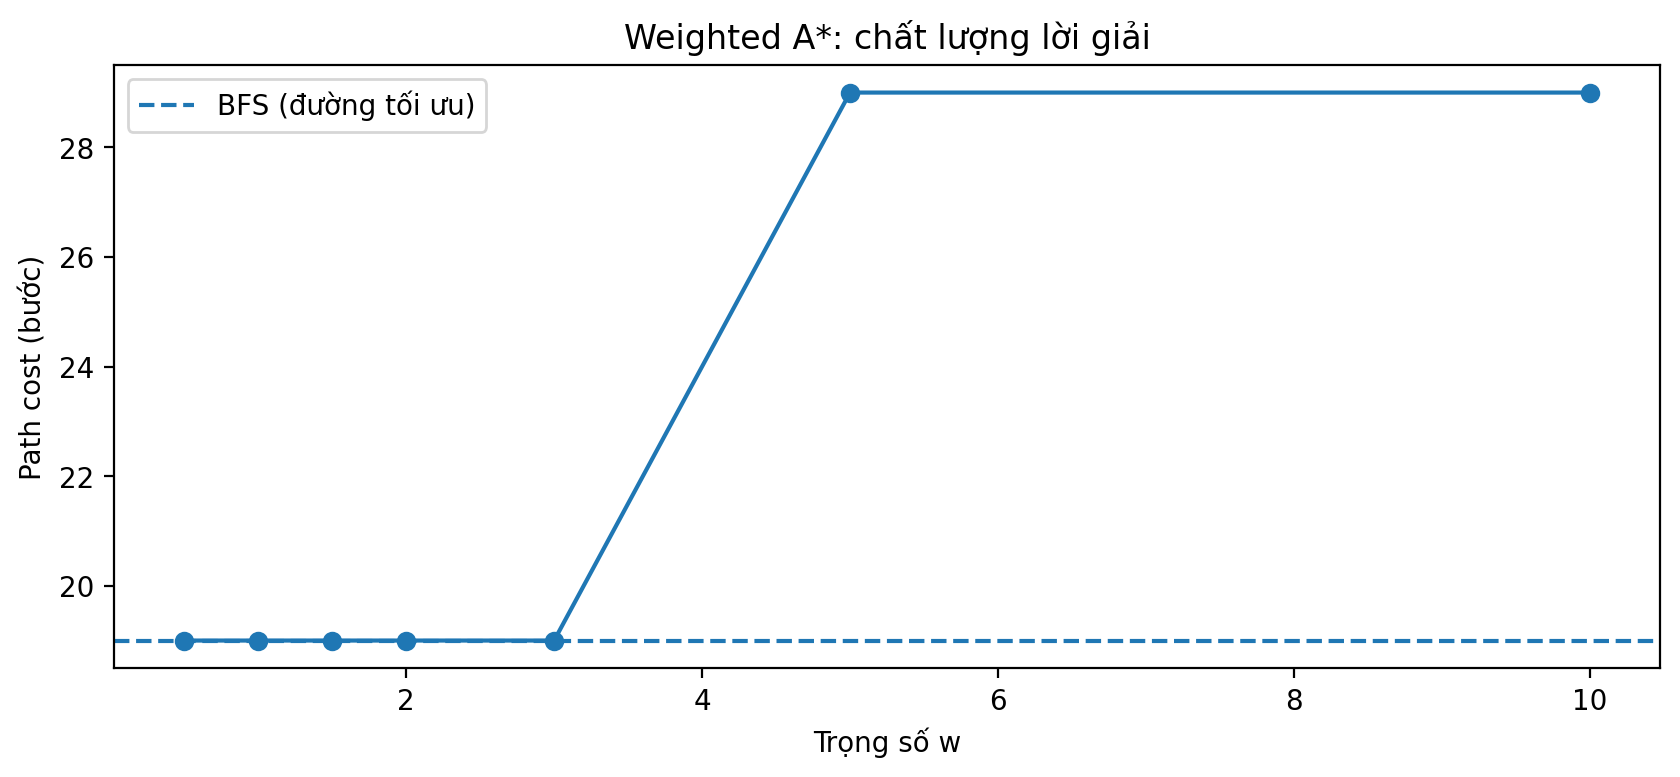

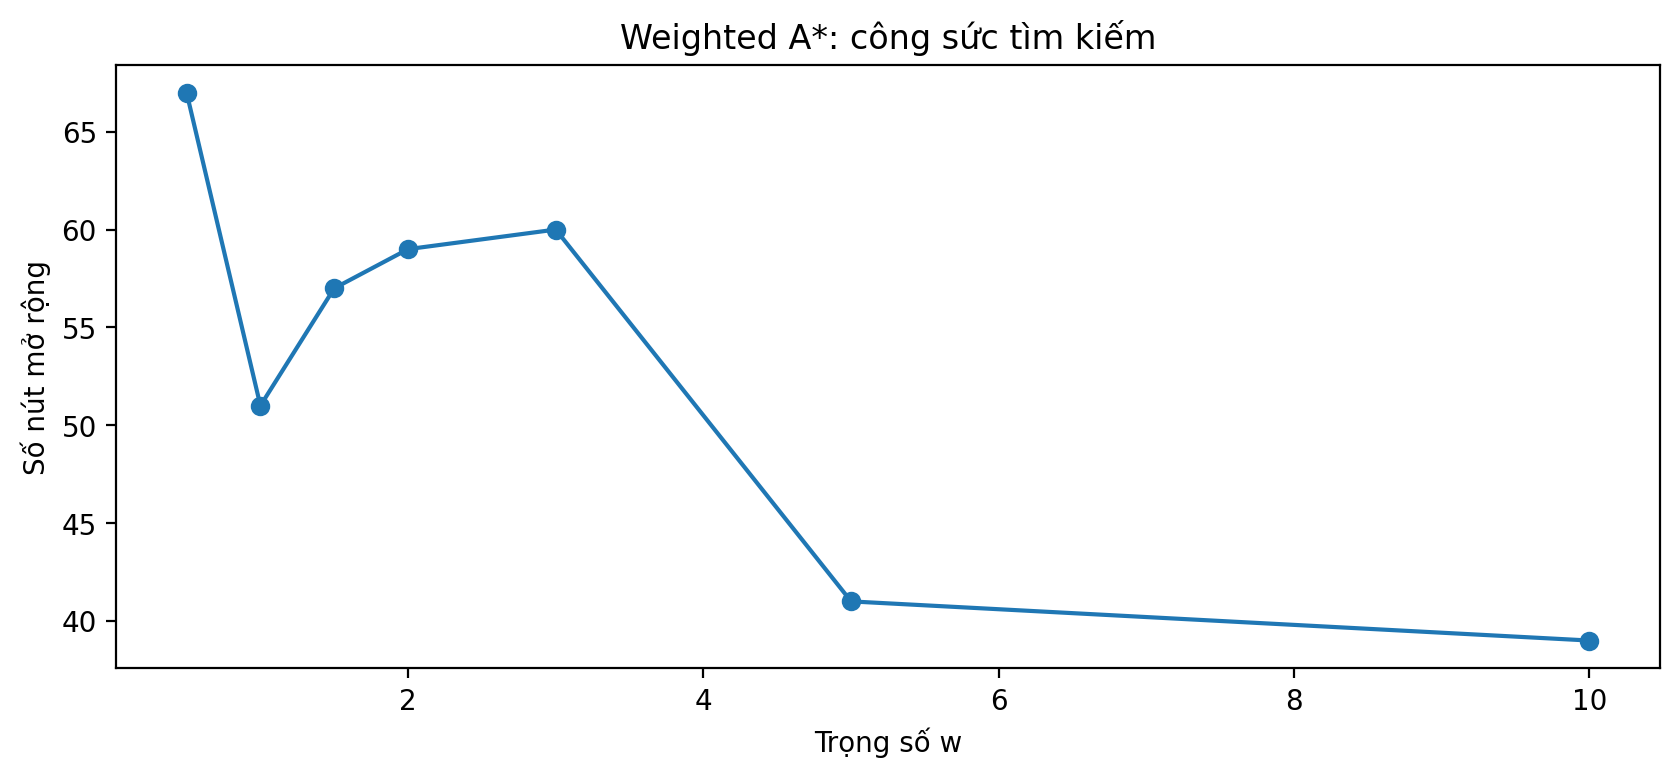

In [40]:
# Hai biểu đồ riêng, tránh dùng các trục tung khác đơn vị trên cùng hình.
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(weighted_bai5['w'], weighted_bai5['Path cost'], marker='o')
ax.axhline(optimal_bai5, linestyle='--', label='BFS (đường tối ưu)')
ax.set(xlabel='Trọng số w', ylabel='Path cost (bước)', title='Weighted A*: chất lượng lời giải')
ax.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(weighted_bai5['w'], weighted_bai5['Nút mở rộng'], marker='o')
ax.set(xlabel='Trọng số w', ylabel='Số nút mở rộng', title='Weighted A*: công sức tìm kiếm')
plt.tight_layout()
plt.show()

### Nhận xét đánh đổi tốc độ – chất lượng

Trên `small_maze`, $w=1$ cho lời giải tối ưu. Nếu $w$ tăng, thuật toán ưu tiên heuristic mạnh hơn, *có thể* bỏ qua một đường ngắn đang nằm trong nhánh tạm thời xa đích. Vì vậy, đánh đổi cần được đánh giá từ cả **path cost**, **số nút mở rộng** và **thời gian đo thực tế**, không chỉ từ một chỉ số.

**Lưu ý phương pháp:** `max_frontier` là số nút được giữ trong frontier tại một thời điểm, không phải dung lượng bộ nhớ đo bằng byte. Các con số khác nhau nếu thay thứ tự mở rộng, quy tắc tie-break hoặc cơ chế cập nhật trạng thái.

## 5.5. Kết luận Bài 5

**(1) GBFS và A***: GBFS sử dụng duy nhất $h(n)$ và thường chọn ngay các nút có vẻ gần đích. A* tính $f(n)=g(n)+h(n)$, giúp hạn chế việc bỏ qua những đường đi có chi phí đã tích lũy nhỏ.

**(2) So sánh BFS và A***: Với chuyển động 4 hướng và chi phí bước bằng 1, BFS tìm được đường ngắn nhất. A* dùng Manhattan và Euclidean cũng tìm được lời giải tối ưu trong thiết lập này, nhưng số nút mở rộng phụ thuộc heuristic và cấu trúc mê cung. Manhattan thường phù hợp hơn Euclidean với lưới bốn hướng.

**(3) Weighted A***: Khi $w$ tăng vượt 1, thuật toán thiên về hướng đích. Một số trường hợp ít mở rộng hơn nhưng đường đi dài hơn; việc giảm nút mở rộng hoặc thời gian không được bảo đảm trên mọi mê cung.

**(4) Ý nghĩa:** Lựa chọn giữa GBFS, A* và Weighted A* cần dựa vào yêu cầu chất lượng lời giải, giới hạn thời gian/bộ nhớ và đặc trưng của không gian trạng thái. Các kết quả minh họa trong notebook được đo trực tiếp từ mã Python và file mê cung đi kèm.